# Лабораторная работа №9: Fine-tuning VLM с помощью LLaMA-Factory

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Преобразовать мультимодальные данные в instruction format.
- Сформировать QLoRA YAML и запустить SFT.
- Сравнить base и adapter, включая OOD slice.


## Теоретическая часть

SFT минимизирует autoregressive loss только на целевом ответе. QLoRA хранит base weights в 4-bit NF4 и обучает low-rank update $\Delta W=BA$, что уменьшает память. LLaMA-Factory фиксирует pipeline в YAML-конфигурации.


### Математическая постановка

$$W'=W_q+\frac{\alpha}{r}BA,\quad B\in\mathbb R^{d\times r},\ A\in\mathbb R^{r\times k}.$$

Обучаются только $A,B$; сравнение проводится с той же base model и evaluation set.


### Материалы

- [LLaMA-Factory](https://github.com/hiyouga/LLaMA-Factory)
- [QLoRA](https://arxiv.org/abs/2305.14314)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Вход — лицензированный предметный корпус `data/lab9/manifest.jsonl` с независимыми train/validation/ID/OOD. Получение и экспертная проверка данных обязательны; файл не заменяется выдуманным изображением. В Colab установите совместимый LLaMA-Factory из зафиксированного commit и запишите commit в отчёт. CLI запускается непосредственно из ноутбука. Полный режим означает фактическое обучение и сравнение; `FAST_DEV_RUN` обучает два шага только для проверки стека. Оценку общей способности выполните на отдельном общем VQA-наборе с заранее выбранной метрикой.

In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
ARTIFACTS = Path(os.getenv('CV_ARTIFACTS', 'artifacts/lab9')); ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path(os.getenv('CV_DATA', 'data/lab9')); DATA_DIR.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
def save_json(name, data):
    (ARTIFACTS/name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
from pathlib import Path
import json, hashlib
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory=DATA_DIR, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text(encoding='utf-8').splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n', encoding='utf-8')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n', encoding='utf-8')
    return manifest
print({'seed': SEED, 'fast_dev_run': FAST_DEV_RUN, 'artifacts': str(ARTIFACTS), 'data': str(DATA_DIR)})

{'seed': 42, 'fast_dev_run': False, 'artifacts': 'artifacts\\lab9', 'data': 'data\\lab9'}


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Задание 1. Манифест и независимые разбиения

*Вес: 1 балл.*

**Постановка.** Загрузите ScienceQA функцией prepare_scienceqa. Сформируйте 512 train и по 64 validation, ID, OOD и general примера с изображениями. ID: natural science, классы 1–6; OOD: тот же предмет, классы 7–12; general: другие предметы. Используйте официальные split и исключите повторные изображения по хешу.

**Результат.** manifest.jsonl и ATTRIBUTION.md.

**Критерий принятия.** Количество записей соответствует протоколу; ни одно изображение не используется в двух разбиениях; версия и лицензия источника указаны.


**Задание 1. Манифест и независимые разбиения**

**Что делали**: загрузили ScienceQA (ревизия `f18b0a70`) функцией `prepare_scienceqa`, разложили примеры с картинками по пяти частям из официальных split и убрали повторные изображения по SHA-256.<br>
**Зачем**: тест должен быть отделён от обучения: одна и та же картинка не может попасть и в train, и в test, иначе оценка завышается.<br>
**Результат**: 768 записей: train 512, validation / ID / OOD / general — по 64; 768 уникальных изображений, 0 пересечений между частями. OOD фактически покрывает только 7–8 классы, general — 63 social science + 1 language science. Файлы `manifest.jsonl`, `ATTRIBUTION.md` (лицензия CC-BY-SA-4.0), `manifest_check.json`.

In [2]:
# Артефакт: проверенный manifest train/validation/ID/OOD/general
import shutil
from collections import Counter
from PIL import Image

MANIFEST = prepare_scienceqa(DATA_DIR, smoke=FAST_DEV_RUN)
ATTRIBUTION = MANIFEST.parent / 'ATTRIBUTION.md'
records = [json.loads(s) for s in MANIFEST.read_text(encoding='utf-8').splitlines() if s.strip()]

SPLITS = ['train', 'validation', 'id_test', 'ood_test', 'general_test']
EXPECTED = {s: (8 if s == 'train' else 4) if FAST_DEV_RUN else (512 if s == 'train' else 64) for s in SPLITS}
counts = Counter(r['split'] for r in records)

# 1) Количество записей по протоколу
assert dict(counts) == EXPECTED, f'counts {dict(counts)} != expected {EXPECTED}'
# 2) Уникальные ID записей
assert len({r['id'] for r in records}) == len(records), 'повторяющиеся id'
# 3) Ни одно изображение не встречается дважды (а значит, и в двух разбиениях)
sha_to_splits = {}
for r in records:
    sha_to_splits.setdefault(r['image_sha256'], set()).add(r['split'])
dup_images = {h: sorted(s) for h, s in sha_to_splits.items() if len(s) > 1}
assert len(sha_to_splits) == len(records), 'одно изображение использовано в нескольких записях'
assert not dup_images, f'изображения в нескольких split: {dup_images}'
# 4) Файлы существуют, и хеш пересчитанного изображения совпадает с записанным
for r in records:
    img = Image.open(r['image']).convert('RGB')
    digest = hashlib.sha256(str(img.size).encode() + img.tobytes()).hexdigest()
    assert digest == r['image_sha256'], f"хеш не совпадает: {r['id']}"
# 5) Правила разбиения: ID — natural science 1–6, OOD — natural science 7–12, general — другие предметы
grade = lambda r: int(r['grade'].removeprefix('grade'))
for r in records:
    if r['split'] in ('train', 'validation', 'id_test'):
        assert r['subject'] == 'natural science' and grade(r) <= 6, r['id']
    elif r['split'] == 'ood_test':
        assert r['subject'] == 'natural science' and grade(r) >= 7, r['id']
    else:
        assert r['subject'] != 'natural science', r['id']
# 6) Официальные split: train/validation из одноимённых, все тесты — только из official test
official = lambda r: r['id'].split('-')[1]
assert all(official(r) == r['split'] for r in records if r['split'] in ('train', 'validation'))
assert all(official(r) == 'test' for r in records if r['split'].endswith('_test'))
# 7) Версия и лицензия источника
attribution_text = ATTRIBUTION.read_text(encoding='utf-8')
assert SCIENCEQA_REVISION in attribution_text and 'CC-BY-SA-4.0' in attribution_text
assert all(r['license'] and SCIENCEQA_REVISION in r['source_url'] for r in records)

# Копии манифеста и атрибуции в папку артефактов лабы
shutil.copy2(MANIFEST, ARTIFACTS / MANIFEST.name)
shutil.copy2(ATTRIBUTION, ARTIFACTS / 'ATTRIBUTION.md')

manifest_check = {
    'manifest': str(MANIFEST), 'fast_dev_run': FAST_DEV_RUN,
    'source': SCIENCEQA_ID, 'revision': SCIENCEQA_REVISION, 'license': 'CC-BY-SA-4.0 (dataset card)',
    'counts': {s: counts[s] for s in SPLITS}, 'expected': EXPECTED,
    'unique_images': len(sha_to_splits), 'cross_split_duplicates': len(dup_images),
    'grades_by_split': {s: dict(sorted(Counter(r['grade'] for r in records if r['split'] == s).items())) for s in SPLITS},
    'subjects_by_split': {s: dict(Counter(r['subject'] for r in records if r['split'] == s)) for s in SPLITS},
}
save_json('manifest_check.json', manifest_check)
print(json.dumps(manifest_check, ensure_ascii=False, indent=2))

{
  "manifest": "C:\\Users\\bogom\\OneDrive\\Документы\\PSY\\6 курс\\МО\\data\\lab9\\manifest.jsonl",
  "fast_dev_run": false,
  "source": "derek-thomas/ScienceQA",
  "revision": "f18b0a70359ebfb41f658fd564208d0355b013f4",
  "license": "CC-BY-SA-4.0 (dataset card)",
  "counts": {
    "train": 512,
    "validation": 64,
    "id_test": 64,
    "ood_test": 64,
    "general_test": 64
  },
  "expected": {
    "train": 512,
    "validation": 64,
    "id_test": 64,
    "ood_test": 64,
    "general_test": 64
  },
  "unique_images": 768,
  "cross_split_duplicates": 0,
  "grades_by_split": {
    "train": {
      "grade2": 67,
      "grade3": 106,
      "grade4": 117,
      "grade5": 98,
      "grade6": 124
    },
    "validation": {
      "grade2": 6,
      "grade3": 16,
      "grade4": 16,
      "grade5": 10,
      "grade6": 16
    },
    "id_test": {
      "grade2": 9,
      "grade3": 16,
      "grade4": 20,
      "grade5": 10,
      "grade6": 9
    },
    "ood_test": {
      "grade7": 26,
   

ScienceQA — набор школьных вопросов с картинками и вариантами ответа

**На какие части делятся данные**

| Часть | Сколько | Откуда | Зачем |
|---|---:|---|---|
| train | 512 | официальный train, natural science 1–6 кл. Только natiral science (естественные науки) 1-6 классы | на этом учим |
| validation | 64 | официальный validation, тот же домен | следим за loss во время обучения |
| ID test | 64 | официальный test, natural science 1–6 кл. | научилась ли модель задаче |
| OOD test | 64 | официальный test, natural science 7–12 кл. | переносится ли умение на более сложные вопросы |
| general test | 64 | официальный test, другие предметы | не разучилась ли модель остальному |

### Задание 2. Визуальный аудит корпуса

*Вес: 1 балл.*

**Постановка.** Декодируйте изображения и постройте сетку примеров с вопросами и правильными буквами. Подсчитайте распределение ответов по каждому split: возможный перевес одной буквы следует учитывать при интерпретации accuracy.

**Результат.** data_profile.json и data_preview.png.

**Критерий принятия.** Показаны реальные изображения; правильная буква соответствует индексированному варианту; представлены частоты всех букв отдельно по split.


**Задание 2. Визуальный аудит корпуса**

**Что делали**: декодировали все 768 изображений, проверили, что правильная буква соответствует варианту в тексте вопроса, нарисовали сетку 5 × 3 примеров и посчитали частоты правильных букв по каждой части.<br>
**Зачем**: перекос букв задаёт базовый уровень accuracy: модель полезна, только если заметно обходит «всегда самую частую букву» и случайное угадывание.<br>
**Результат**: битых файлов 0. В train правильные A — 209, B — 230, C — 72, D — 1 из 512. Базовые уровни (самая частая буква / угадывание): ID 0.42 / 0.43, OOD 0.42 / 0.37, general 0.33 / 0.25. Файлы `data_profile.json`, `data_preview.png`.

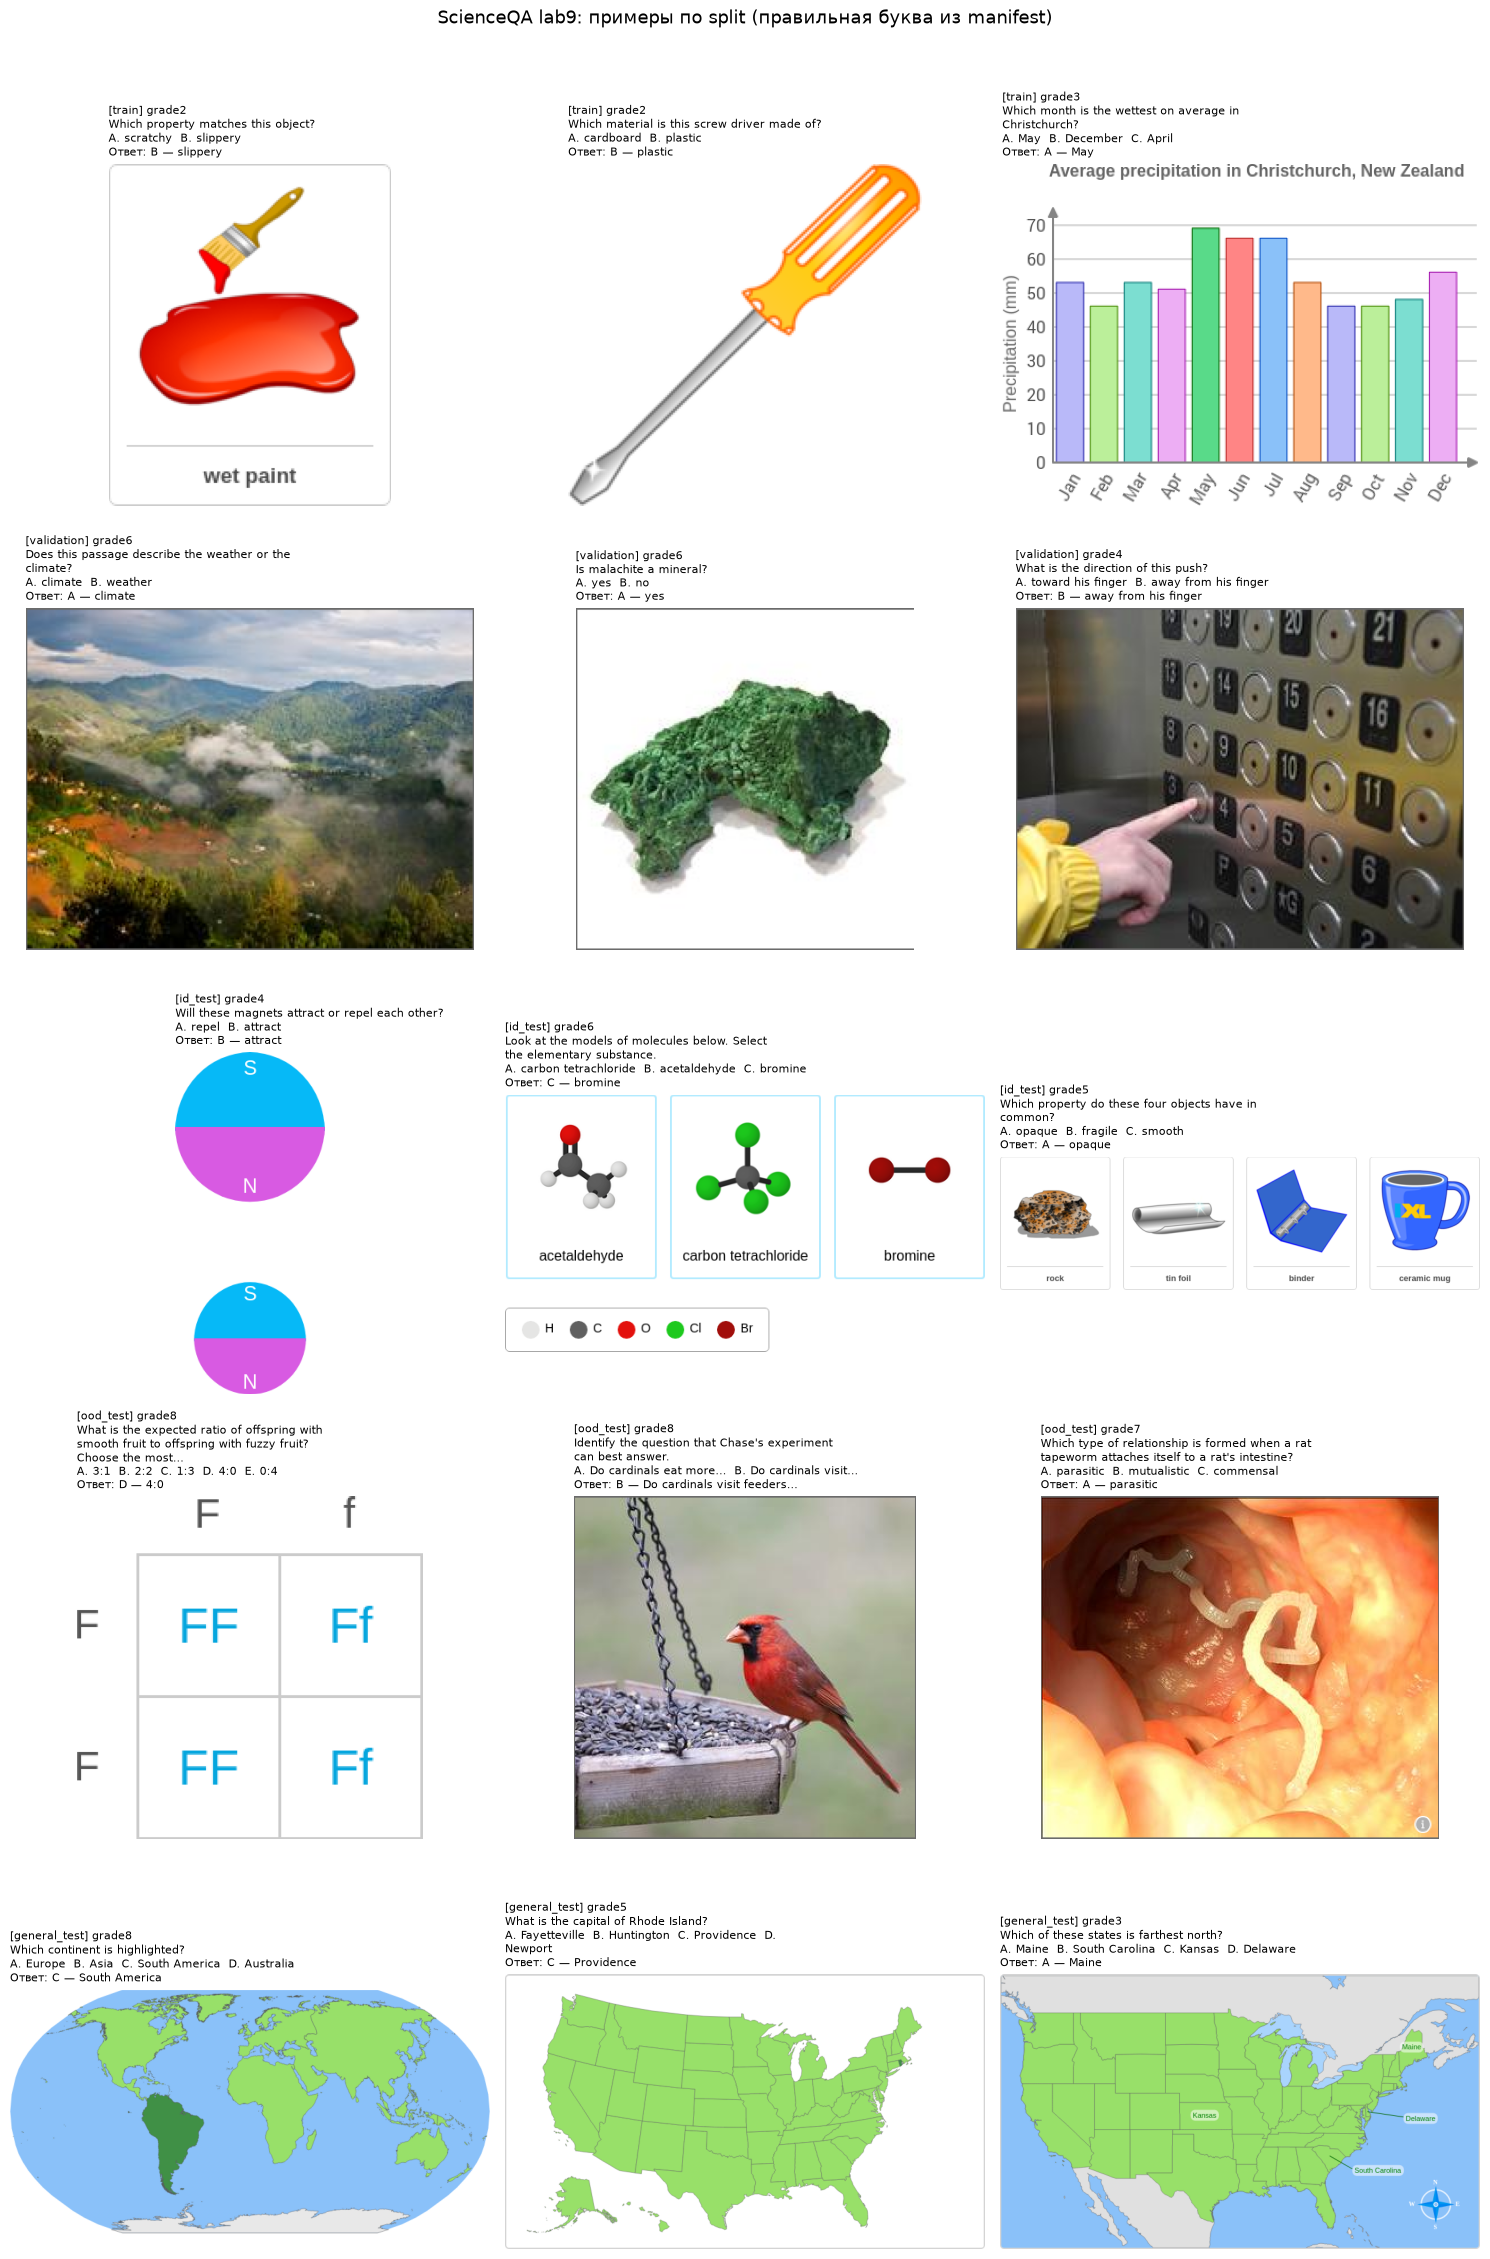

                A    B   C   D  E    n  majority_acc  random_acc
train         209  230  72   1  0  512        0.4492      0.4268
validation     24   32   8   0  0   64        0.5000      0.4401
id_test        26   27  11   0  0   64        0.4219      0.4258
ood_test       25   27   9   3  0   64        0.4219      0.3721
general_test   13   21  17  13  0   64        0.3281      0.2526
Сохранено: artifacts\lab9\data_profile.json artifacts\lab9\data_preview.png


In [3]:
# Артефакт: существующие файлы изображений и непустые вопросы и ответы
import textwrap
import matplotlib.pyplot as plt

# 1) Декодирование всех изображений и проверка полей
image_sizes, bad = {}, []
for r in records:
    try:
        with Image.open(r['image']) as im:
            im.verify()                       # целостность файла
        with Image.open(r['image']) as im:
            image_sizes[r['id']] = im.convert('RGB').size   # фактическое декодирование
    except Exception as e:
        bad.append((r['id'], repr(e)))
    assert r['question'].strip() and r['answer'].strip(), f"пустой вопрос/ответ: {r['id']}"
    # правильная буква соответствует индексированному варианту
    assert 0 <= r['answer_index'] < len(r['choices']), r['id']
    assert r['answer'] == chr(65 + r['answer_index']), r['id']
    assert f"{r['answer']}. {r['choices'][r['answer_index']]}" in r['question'], r['id']
assert not bad, f'не декодируются: {bad[:5]}'

# 2) Распределение правильных букв по каждому split
max_choices = max(len(r['choices']) for r in records)
LETTERS = [chr(65 + i) for i in range(max_choices)]
profile = {'n_records': len(records), 'letters': LETTERS, 'splits': {}}
for s in SPLITS:
    rs = [r for r in records if r['split'] == s]
    freq = Counter(r['answer'] for r in rs)
    n_choices = Counter(len(r['choices']) for r in rs)
    majority_letter, majority_n = max(freq.items(), key=lambda kv: kv[1])
    profile['splits'][s] = {
        'n': len(rs),
        'answer_counts': {L: freq.get(L, 0) for L in LETTERS},
        'answer_share': {L: round(freq.get(L, 0) / len(rs), 4) for L in LETTERS},
        'n_choices_distribution': {str(k): v for k, v in sorted(n_choices.items())},
        # ориентиры для интерпретации accuracy
        'majority_letter': majority_letter,
        'majority_baseline_acc': round(majority_n / len(rs), 4),
        'random_guess_expected_acc': round(float(np.mean([1 / len(r['choices']) for r in rs])), 4),
        'image_size_min': list(map(int, np.min([image_sizes[r['id']] for r in rs], axis=0))),
        'image_size_max': list(map(int, np.max([image_sizes[r['id']] for r in rs], axis=0))),
    }
save_json('data_profile.json', profile)

# 3) Сетка реальных примеров: по 3 изображения из каждого split
rng = random.Random(SEED)
PER_SPLIT = 3
fig, axes = plt.subplots(len(SPLITS), PER_SPLIT, figsize=(5 * PER_SPLIT, 4.6 * len(SPLITS)))
for row, s in enumerate(SPLITS):
    sample = rng.sample([r for r in records if r['split'] == s], PER_SPLIT)
    for col, r in enumerate(sample):
        ax = axes[row, col]
        ax.imshow(Image.open(r['image']).convert('RGB'))
        ax.axis('off')
        stem = textwrap.shorten(r['question'].split('\n')[0], 110, placeholder='…')
        opts = '  '.join(f'{chr(65+i)}. {textwrap.shorten(c, 22, placeholder="…")}' for i, c in enumerate(r['choices']))
        ax.set_title(f"[{s}] {r['grade']}\n" + '\n'.join(textwrap.wrap(stem, 48)) +
                     '\n' + '\n'.join(textwrap.wrap(opts, 52)) +
                     f"\nОтвет: {r['answer']} — {textwrap.shorten(r['choices'][r['answer_index']], 30, placeholder='…')}",
                     fontsize=8, loc='left')
fig.suptitle('ScienceQA lab9: примеры по split (правильная буква из manifest)', fontsize=13, y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.975))   # верхние 2.5% высоты — под общий заголовок
fig.savefig(ARTIFACTS / 'data_preview.png', dpi=110, bbox_inches='tight')
plt.show()

# 4) Таблица частот букв
import pandas as pd
freq_table = pd.DataFrame({s: profile['splits'][s]['answer_counts'] for s in SPLITS}).T
freq_table['n'] = freq_table.sum(axis=1)
freq_table['majority_acc'] = [profile['splits'][s]['majority_baseline_acc'] for s in SPLITS]
freq_table['random_acc'] = [profile['splits'][s]['random_guess_expected_acc'] for s in SPLITS]
print(freq_table.to_string())
print('Сохранено:', ARTIFACTS / 'data_profile.json', ARTIFACTS / 'data_preview.png')

**Базовые уровни accuracy**

**`majority_acc`** — точность стратегии «всегда отвечать самой частой буквой»:

$$\text{majority\_acc} = \frac{\text{сколько раз встретилась самая частая буква}}{n}$$

**`random_acc`** — ожидаемая точность случайного угадывания. Если в вопросе $k$ вариантов, шанс угадать равен $1/k$, и это значение усредняется по всем вопросам:

$$\text{random\_acc} = \frac{1}{n}\sum_{i=1}^{n}\frac{1}{k_i}$$

### Задание 3. Экспорт мультимодального датасета

*Вес: 1 балл.*

**Постановка.** Преобразуйте записи в ShareGPT: сообщение пользователя содержит один маркер <image> и вопрос с вариантами, ответ ассистента — правильную букву. Зарегистрируйте train и validation в dataset_info.json.

**Результат.** train.json, validation.json и dataset_info.json.

**Критерий принятия.** Пути изображений разрешаются; роли и столбцы соответствуют формату LLaMA-Factory; test не попал в обучение.


**Задание 3. Экспорт мультимодального датасета**

**Что делали**: перевели train и validation в формат ShareGPT: реплика `user` — `<image>` + вопрос с вариантами, реплика `assistant` — правильная буква, путь к картинке — в `images`. Зарегистрировали оба набора в `dataset_info.json`.<br>
**Зачем**: LLaMA-Factory читает данные только в своём формате и находит их по имени из `dataset_info.json`.<br>
**Результат**: `train.json` — 512 диалогов, `validation.json` — 64; в каждом ровно один `<image>` и одна картинка; наборы `lab9_scienceqa_train` и `lab9_scienceqa_validation`; тестовых примеров в обучении — 0.

In [4]:
# Артефакт: ShareGPT JSON и dataset_info.json
# Формат LLaMA-Factory (sharegpt, multimodal): messages с ролями user/assistant + список images.
# Число маркеров <image> в сообщениях должно совпадать с длиной images (здесь 1 и 1).
LF_DATA = ARTIFACTS / 'lf_data'; LF_DATA.mkdir(parents=True, exist_ok=True)
DATASET_NAMES = {'train': 'lab9_scienceqa_train', 'validation': 'lab9_scienceqa_validation'}

def to_sharegpt(r):
    assert '<image>' not in r['question'], r['id']
    return {
        'id': r['id'],
        'messages': [
            {'role': 'user', 'content': '<image>' + r['question']},
            {'role': 'assistant', 'content': r['answer']},
        ],
        'images': [Path(r['image']).resolve().as_posix()],
    }

exports = {}
for split in ('train', 'validation'):
    rows = [to_sharegpt(r) for r in records if r['split'] == split]
    (LF_DATA / f'{split}.json').write_text(json.dumps(rows, ensure_ascii=False, indent=1), encoding='utf-8')
    exports[split] = rows

dataset_info = {
    DATASET_NAMES[split]: {
        'file_name': f'{split}.json',
        'formatting': 'sharegpt',
        'columns': {'messages': 'messages', 'images': 'images'},
        'tags': {'role_tag': 'role', 'content_tag': 'content',
                 'user_tag': 'user', 'assistant_tag': 'assistant'},
    }
    for split in ('train', 'validation')
}
(LF_DATA / 'dataset_info.json').write_text(json.dumps(dataset_info, ensure_ascii=False, indent=2), encoding='utf-8')

# Проверки критерия принятия
test_ids = {r['id'] for r in records if r['split'].endswith('_test')}
test_images = {Path(r['image']).resolve().as_posix() for r in records if r['split'].endswith('_test')}
for split, rows in exports.items():
    assert len(rows) == EXPECTED[split], (split, len(rows))
    for row in rows:
        roles = [m['role'] for m in row['messages']]
        assert roles == ['user', 'assistant'], row['id']
        assert row['messages'][0]['content'].count('<image>') == 1 == len(row['images']), row['id']
        assert row['messages'][1]['content'] in LETTERS, row['id']
        assert Path(row['images'][0]).is_file(), f"путь не разрешается: {row['images'][0]}"
        assert row['id'] not in test_ids and row['images'][0] not in test_images, f"test в обучении: {row['id']}"
assert not {r['id'] for r in exports['train']} & {r['id'] for r in exports['validation']}
reloaded = json.loads((LF_DATA / 'dataset_info.json').read_text(encoding='utf-8'))
assert all((LF_DATA / v['file_name']).is_file() for v in reloaded.values())

print('dataset_dir:', LF_DATA)
print({k: len(v) for k, v in exports.items()}, '| test в обучении: 0')
print(json.dumps(exports['train'][0], ensure_ascii=False, indent=2))

dataset_dir: artifacts\lab9\lf_data
{'train': 512, 'validation': 64} | test в обучении: 0
{
  "id": "scienceqa-train-9",
  "messages": [
    {
      "role": "user",
      "content": "<image>Which of these organisms contains matter that was once part of the phytoplankton?\nA. black rockfish\nB. sea otter\nReturn only the letter of the correct option."
    },
    {
      "role": "assistant",
      "content": "A"
    }
  ],
  "images": [
    "C:/Users/bogom/OneDrive/Документы/PSY/6 курс/МО/data/lab9/7059b2a9d6213ab2b6bc531c6adaa60811f86552fb2ac3b6acf1244b0485c5b9.png"
  ]
}


**ShareGPT** — сторонний сервис, где пользователи делились своими диалогами с ChatGPT.

### Задание 4. Конфигурация QLoRA SFT

*Вес: 1 балл.*

**Постановка.** Настройте Qwen2.5-VL-3B-Instruct, NF4, LoRA rank 8 и alpha 16, batch 1 с accumulation 16, learning rate 1e-4 и 100 шагов. Включите validation каждые 20 шагов.

**Результат.** sft.yaml.

**Критерий принятия.** YAML содержит реальные идентификаторы данных и модели, включает do_train/do_eval и сохраняет checkpoint; полный режим не ограничен двумя smoke-шагами.


**Задание 4. Конфигурация QLoRA SFT**

**Что делали**: описали весь запуск обучения в `sft.yaml`: Qwen2.5-VL-3B-Instruct, 4-bit NF4 (`quantization_method: bnb`), LoRA rank 8 / alpha 16, batch 4 × accumulation 4, lr 1e-4, 100 шагов, validation и checkpoint каждые 20 шагов.<br>
**Зачем**: LLaMA-Factory обучает модель по этому файлу; квантизация вместе с LoRA даёт QLoRA, которая помещается в 12 ГБ.<br>
**Результат**: эффективный batch 16, 100 шагов = 1600 примеров ≈ 3.12 эпохи, bf16. Обучается 14 966 784 параметров (0.40% модели). По замеру пик памяти шага с NF4 около 7 ГБ; значение `bitsandbytes` вместо `bnb` молча отключало квантизацию (7 ГБ весов вместо 2.2 ГБ).

In [5]:
# Артефакт: artifacts/sft.yaml с настоящей Qwen2.5-VL
import yaml, torch

MODEL_ID = 'Qwen/Qwen2.5-VL-3B-Instruct'
ADAPTER_DIR = ARTIFACTS / 'lab9_adapter'
SFT_YAML = ARTIFACTS / 'sft.yaml'
use_bf16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()

SFT_CFG = {
    # --- модель и QLoRA (4-bit NF4) ---
    'model_name_or_path': MODEL_ID,
    'trust_remote_code': True,
    'image_max_pixels': 262144,          # 512*512: ограничение числа визуальных токенов
    'quantization_bit': 4,
    'quantization_method': 'bnb',        # именно 'bnb': с другим значением LLaMA-Factory молча НЕ квантует
    'quantization_type': 'nf4',
    'double_quantization': True,
    # --- метод ---
    'stage': 'sft',
    'do_train': True,
    'finetuning_type': 'lora',
    'lora_rank': 8,
    'lora_alpha': 16,
    'lora_dropout': 0.05,
    'lora_target': 'all',                # все linear-слои языковой части
    'freeze_vision_tower': True,
    # --- данные (имена из dataset_info.json) ---
    'dataset_dir': LF_DATA.resolve().as_posix(),
    'dataset': DATASET_NAMES['train'],
    'eval_dataset': DATASET_NAMES['validation'],
    'template': 'qwen2_vl',
    'cutoff_len': 2048,
    'overwrite_cache': True,
    'dataloader_num_workers': 0,         # Windows: без форка процессов
    # --- вывод и checkpoint ---
    # overwrite_output_dir не задаётся: в transformers 5.x его нет, LLaMA-Factory считает его False
    # и не затирает существующие checkpoint (нужно для resume)
    'output_dir': ADAPTER_DIR.resolve().as_posix(),
    'logging_steps': 1 if FAST_DEV_RUN else 5,
    'save_strategy': 'steps',
    'save_steps': 1 if FAST_DEV_RUN else 20,
    'plot_loss': True,
    'report_to': 'none',
    # --- оптимизация ---
    # Постановка: batch 1 x accumulation 16. Здесь 4 x 4 — тот же эффективный batch 16 (тот же усреднённый
    # градиент на шаг), но GPU обрабатывает 4 изображения за проход. С 4-bit NF4 замер пика шага: ~7 ГБ из 12.
    'per_device_train_batch_size': 4,
    'gradient_accumulation_steps': 4,    # эффективный batch = 4 * 4 = 16
    'learning_rate': 1.0e-4,
    'max_steps': 2 if FAST_DEV_RUN else 100,
    'lr_scheduler_type': 'cosine',
    'warmup_ratio': 0.1,
    'bf16': use_bf16,
    'fp16': not use_bf16,
    'gradient_checkpointing': True,
    'seed': SEED,
    # --- validation ---
    'do_eval': True,
    'per_device_eval_batch_size': 1,
    'eval_strategy': 'steps',
    'eval_steps': 1 if FAST_DEV_RUN else 20,
}

SFT_YAML.write_text(yaml.safe_dump(SFT_CFG, sort_keys=False, allow_unicode=True), encoding='utf-8')

# Проверки критерия принятия
cfg = yaml.safe_load(SFT_YAML.read_text(encoding='utf-8'))
ds_info = json.loads((Path(cfg['dataset_dir']) / 'dataset_info.json').read_text(encoding='utf-8'))
assert cfg['model_name_or_path'] == 'Qwen/Qwen2.5-VL-3B-Instruct'
assert cfg['dataset'] in ds_info and cfg['eval_dataset'] in ds_info, 'идентификаторы данных не зарегистрированы'
assert cfg['do_train'] and cfg['do_eval']
assert cfg['quantization_bit'] == 4 and cfg['quantization_method'] == 'bnb' and cfg['quantization_type'] == 'nf4'
assert (cfg['lora_rank'], cfg['lora_alpha']) == (8, 16)
assert cfg['per_device_train_batch_size'] * cfg['gradient_accumulation_steps'] == 16, 'эффективный batch должен быть 16'
assert cfg['learning_rate'] == 1e-4 and cfg['save_strategy'] == 'steps' and cfg['save_steps'] > 0
if not FAST_DEV_RUN:
    assert cfg['max_steps'] == 100 and cfg['eval_steps'] == 20, 'полный режим не должен быть smoke'

n_train = len(exports['train'])
eff_batch = cfg['per_device_train_batch_size'] * cfg['gradient_accumulation_steps']
print(f"max_steps={cfg['max_steps']}, batch {cfg['per_device_train_batch_size']} x accumulation "
      f"{cfg['gradient_accumulation_steps']} = эффективный {eff_batch} -> "
      f"{cfg['max_steps'] * eff_batch / n_train:.2f} эпох по {n_train} примерам; precision={'bf16' if use_bf16 else 'fp16'}")
print(SFT_YAML.read_text(encoding='utf-8'))

max_steps=100, batch 4 x accumulation 4 = эффективный 16 -> 3.12 эпох по 512 примерам; precision=bf16
model_name_or_path: Qwen/Qwen2.5-VL-3B-Instruct
trust_remote_code: true
image_max_pixels: 262144
quantization_bit: 4
quantization_method: bnb
quantization_type: nf4
double_quantization: true
stage: sft
do_train: true
finetuning_type: lora
lora_rank: 8
lora_alpha: 16
lora_dropout: 0.05
lora_target: all
freeze_vision_tower: true
dataset_dir: C:/Users/bogom/OneDrive/Документы/PSY/6 курс/МО/artifacts/lab9/lf_data
dataset: lab9_scienceqa_train
eval_dataset: lab9_scienceqa_validation
template: qwen2_vl
cutoff_len: 2048
overwrite_cache: true
dataloader_num_workers: 0
output_dir: C:/Users/bogom/OneDrive/Документы/PSY/6 курс/МО/artifacts/lab9/lab9_adapter
logging_steps: 5
save_strategy: steps
save_steps: 20
plot_loss: true
report_to: none
per_device_train_batch_size: 4
gradient_accumulation_steps: 4
learning_rate: 0.0001
max_steps: 100
lr_scheduler_type: cosine
warmup_ratio: 0.1
bf16: true
fp16

**Что настроено в `sft.yaml`**

| Что настроили | Параметры | Зачем |
|---|---|---|
| **Модель** | `Qwen/Qwen2.5-VL-3B-Instruct`, шаблон `qwen2_vl` | кого дообучаем |
| **Квантизация** | 4 бита, NF4, `quantization_method: bnb` | базовые веса сжаты и заморожены |
| **LoRA** | rank 8, alpha 16, dropout 0.05, `lora_target: all` | какие маленькие матрицы добавить и обучать |
| **Данные** | `lab9_scienceqa_train`, `lab9_scienceqa_validation`, `dataset_dir` | на чём учимся и проверяемся |
| **Оптимизация** | batch 4 × accumulation 4, lr 1e-4, 100 шагов, cosine, warmup 10% | как именно учим |
| **Проверки и сохранение** | `eval_steps: 20`, `save_steps: 20`, `output_dir` | как часто проверять и сохранять checkpoint |

Именно квантизация вместе с LoRA и даёт **QLoRA**: 4-битная замороженная модель плюс обучаемый адаптер.

**Что означают параметры LoRA**

- **`lora_rank: 8`** — размер добавочных матриц $B$ и $A$. Больше ранг — больше обучаемых параметров и гибкости, но больше риск переобучения.
- **`lora_alpha: 16`** — масштаб добавки. Итоговый множитель $\alpha/r = 16/8 = 2$ в формуле $W' = W_q + \frac{\alpha}{r}BA$.
- **`lora_target: all`** — адаптеры ставятся на все linear-слои языковой части.
- **`freeze_vision_tower: true`** — визуальная часть не обучается.

### Задание 5. Возобновление обучения

*Вес: 1 балл.*

**Постановка.** Реализуйте выбор последнего checkpoint по числовому global step. Отсутствие checkpoint означает новый запуск; существующий должен принадлежать той же конфигурации. Объясните отличие загрузки весов от восстановления состояния оптимизатора.

**Результат.** resume_protocol.json и обновлённый sft.yaml.

**Критерий принятия.** Выбор не основан на лексикографическом порядке; зафиксированы выбранный путь либо null и режим нового/возобновляемого запуска.


**Задание 5. Возобновление обучения**

**Что делали**: нашли последний полный checkpoint по номеру шага как числу, проверили отпечаток конфигурации (хеш `sft.yaml` + данных) и выбрали режим `new` или `resume`.<br>
**Зачем**: после обрыва обучение продолжается с того же места, а чужие прогоны (другая конфигурация) не смешиваются с текущим.<br>
**Результат**: финальный прогон запущен в режиме `new`; после него выбран `checkpoint-100` (global_step = 100 = max_steps, обучение не повторяется). Ранее прерванный прогон продолжался с `checkpoint-20`; прогоны других конфигураций отложены в `lab9_adapter_stale_*`. Файл `resume_protocol.json`.

In [6]:
# Артефакт: выбранный checkpoint того же прогона
import re

CKPT_RE = re.compile(r'^checkpoint-(\d+)$')
RUN_CONFIG = ARTIFACTS / 'lab9_adapter.run_config.json'   # отпечаток прогона хранится рядом, не внутри output_dir
REQUIRED_CKPT_FILES = ['adapter_model.safetensors', 'trainer_state.json', 'optimizer.pt', 'scheduler.pt']

def step_of(name):
    m = CKPT_RE.match(Path(name).name)
    return int(m.group(1)) if m else None

def run_fingerprint(cfg):
    """Хеш всего, что определяет траекторию обучения: конфиг (без resume) + содержимое данных."""
    core = {k: v for k, v in cfg.items() if k != 'resume_from_checkpoint'}
    data_hash = {f: hashlib.sha256((Path(cfg['dataset_dir']) / f).read_bytes()).hexdigest()
                 for f in ('train.json', 'validation.json', 'dataset_info.json')}
    blob = json.dumps({'cfg': core, 'data': data_hash}, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(blob.encode()).hexdigest(), data_hash

def scan_checkpoints(output_dir):
    out = []
    for p in Path(output_dir).glob('checkpoint-*'):
        step = step_of(p.name)
        if step is None or not p.is_dir():
            continue
        missing = [f for f in REQUIRED_CKPT_FILES if not (p / f).is_file()]
        state_step = None
        if (p / 'trainer_state.json').is_file():
            state_step = json.loads((p / 'trainer_state.json').read_text(encoding='utf-8')).get('global_step')
        out.append({'path': p.resolve().as_posix(), 'step': step, 'trainer_state_global_step': state_step,
                    'missing_files': missing, 'valid': not missing and state_step == step})
    return sorted(out, key=lambda c: c['step'])          # числовой порядок

def latest_checkpoint(output_dir):
    valid = [c for c in scan_checkpoints(output_dir) if c['valid']]
    return max(valid, key=lambda c: c['step']) if valid else None   # max по int(step), не по строке

# Демонстрация: лексикографический порядок ошибается, числовой — нет
demo = ['checkpoint-20', 'checkpoint-100', 'checkpoint-80']
assert max(demo) == 'checkpoint-80' and max(demo, key=step_of) == 'checkpoint-100'

# --- Решение: новый запуск или возобновление ---
cfg = {k: v for k, v in SFT_CFG.items() if k != 'resume_from_checkpoint'}
fingerprint, data_hash = run_fingerprint(cfg)
output_dir = Path(cfg['output_dir'])
candidates = scan_checkpoints(output_dir) if output_dir.exists() else []
prev = json.loads(RUN_CONFIG.read_text(encoding='utf-8')) if RUN_CONFIG.exists() else None
stale_moved_to, reason = None, None

if output_dir.exists() and any(output_dir.iterdir()) and (prev is None or prev['fingerprint'] != fingerprint):
    # Чужой прогон (другая конфигурация/данные, например smoke) — не продолжаем его, а откладываем в сторону
    stale_moved_to = output_dir.with_name(f"{output_dir.name}_stale_{(prev or {}).get('fingerprint', 'unknown')[:8]}_{int(time.time())}")
    output_dir.rename(stale_moved_to)
    reason = 'в output_dir найден прогон другой конфигурации — перемещён, начинается новый запуск'
    candidates = []

selected = latest_checkpoint(output_dir) if output_dir.exists() else None
if selected is None:
    mode = 'new'
    reason = reason or ('checkpoint нет — новый запуск' if not candidates else 'нет полного checkpoint — новый запуск')
    if output_dir.exists() and not any(output_dir.iterdir()):
        output_dir.rmdir()
    elif output_dir.exists():
        # неполные остатки без валидного checkpoint: LLaMA-Factory откажется писать в непустую папку
        stale_moved_to = output_dir.with_name(f'{output_dir.name}_incomplete_{int(time.time())}')
        output_dir.rename(stale_moved_to)
else:
    mode = 'resume'
    reason = f"тот же отпечаток конфигурации, последний валидный global_step={selected['step']}"
    if selected['step'] >= cfg['max_steps']:
        reason += f" (>= max_steps={cfg['max_steps']}: обучение уже завершено, Trainer только восстановит состояние)"

# --- Обновлённый sft.yaml: resume задан явно (иначе LLaMA-Factory сам подхватил бы последний checkpoint) ---
SFT_CFG = dict(cfg)
if selected is not None:
    SFT_CFG['resume_from_checkpoint'] = selected['path']
SFT_YAML.write_text(yaml.safe_dump(SFT_CFG, sort_keys=False, allow_unicode=True), encoding='utf-8')
RUN_CONFIG.write_text(json.dumps({'fingerprint': fingerprint, 'data_sha256': data_hash, 'config': cfg},
                                 ensure_ascii=False, indent=2), encoding='utf-8')

resume_protocol = {
    'output_dir': output_dir.resolve().as_posix(),
    'config_fingerprint': fingerprint,
    'previous_fingerprint': (prev or {}).get('fingerprint'),
    'same_config': prev is not None and prev['fingerprint'] == fingerprint,
    'selection_rule': 'max(int(N)) по папкам checkpoint-N с полным набором файлов и trainer_state.global_step == N; не лексикографически',
    'candidates': candidates,
    'selected_checkpoint': selected['path'] if selected else None,
    'mode': mode,
    'reason': reason,
    'stale_run_moved_to': stale_moved_to.as_posix() if stale_moved_to else None,
    'weights_vs_optimizer_state': {
        'load_weights_only': ('Загружаются только параметры адаптера (adapter_model.safetensors). '
                              'Это новый запуск с шага 0: моменты AdamW (m, v) обнулены, cosine-scheduler снова '
                              'начинает с warmup, порядок батчей и RNG стартуют заново — траектория отличается '
                              'от непрерывного обучения, а шаги считаются повторно.'),
        'resume_training_state': ('resume_from_checkpoint восстанавливает веса и optimizer.pt (моменты AdamW), '
                                  'scheduler.pt (текущий learning rate), trainer_state.json (global_step, история '
                                  'loss/eval) и rng_state (порядок данных, dropout). Обучение продолжается с шага N '
                                  'до max_steps так, как если бы не прерывалось.'),
    },
}
save_json('resume_protocol.json', resume_protocol)
print(json.dumps({k: resume_protocol[k] for k in ('mode', 'selected_checkpoint', 'reason', 'stale_run_moved_to', 'same_config')},
                 ensure_ascii=False, indent=2))

{
  "mode": "resume",
  "selected_checkpoint": "C:/Users/bogom/OneDrive/Документы/PSY/6 курс/МО/artifacts/lab9/lab9_adapter/checkpoint-100",
  "reason": "тот же отпечаток конфигурации, последний валидный global_step=100 (>= max_steps=100: обучение уже завершено, Trainer только восстановит состояние)",
  "stale_run_moved_to": null,
  "same_config": true
}


**Загрузка весов и восстановление состояния обучения**

| | Загрузить только веса адаптера | `resume_from_checkpoint` |
|---|---|---|
| Что восстанавливается | только `adapter_model.safetensors` | веса + `optimizer.pt` + `scheduler.pt` + `trainer_state.json` + состояние RNG |
| Счётчик шагов | снова с 0 | продолжается с сохранённого шага (у нас — 20) |
| Моменты Adam ($m$, $v$) | обнулены, оптимизатор «разгоняется» заново | сохранены |
| Learning rate | снова warmup с начала cosine-расписания | с того места, где остановились |
| Порядок данных | заново | тот же, что был бы без прерывания |
| Итог | по сути новое обучение, стартующее с уже частично обученных весов | продолжение, эквивалентное непрерывному обучению |

### Задание 6. Обучение в LLaMA-Factory

*Вес: 1 балл.*

**Постановка.** Выполните llamafactory-cli train с сохранением полного лога. Проверьте фактически выполненное число шагов и наличие обученного адаптера.

**Результат.** lab9_adapter, train.log и version.json.

**Критерий принятия.** Процесс завершился без ошибки; сохранены adapter_model.safetensors и trainer_state.json; запуск с FAST_DEV_RUN=True не принимается за полный эксперимент.


Обучили LoRA-адаптер. Базовые веса Qwen были заморожены в 4 битах, обучались только матрицы адаптера: около 15 млн параметров, 0.4% модели. За 100 шагов получился файл lab9_adapter/adapter_model.safetensors на 57 МБ.

**Задание 6. Обучение в LLaMA-Factory**

**Что делали**: запустили `llamafactory-cli train` (v0.9.5, отдельное окружение `.venv-lf`), сохранили полный лог и проверили число шагов и адаптер.<br>
**Зачем**: получить LoRA-адаптер, который потом сравнивается с исходной моделью.<br>
**Результат**: 100 / 100 шагов за 11 мин 44 с (≈ 5.6–5.9 с/шаг), `train_runtime` 12 мин 07 с. Train loss к концу 0.050 (среднее 0.101); eval loss 0.126 → 0.112 (шаг 40) → 0.117 (шаг 100) — лёгкое переобучение. Адаптер `adapter_model.safetensors` — 57 МБ; файлы `train.log`, `version.json`.

In [7]:
# Артефакт: обученный lab9_adapter и train.log
# LLaMA-Factory ставится в ОТДЕЛЬНОЕ окружение .venv-lf из зафиксированного commit:
# в основном .venv он понизил бы transformers/datasets/pandas и сломал бы другие лабы.
import subprocess, sys, platform

LF_REPO = 'https://github.com/hiyouga/LLaMA-Factory.git'
LF_COMMIT = '7af909522a951e3ad9f022ea6f88b6755257eaa5'      # tag v0.9.5
LF_VENV = Path('.venv-lf').resolve()
LF_BIN = LF_VENV / ('Scripts' if os.name == 'nt' else 'bin')
LF_PY = LF_BIN / ('python.exe' if os.name == 'nt' else 'python')
LF_CLI = LF_BIN / ('llamafactory-cli.exe' if os.name == 'nt' else 'llamafactory-cli')
TORCH_PINS = ['torch==2.11.0', 'torchvision==0.26.0', 'torchaudio==2.11.0']
TORCH_INDEX = 'https://download.pytorch.org/whl/cu128'
TRAIN_LOG = ARTIFACTS / 'train.log'

# Окружение дочерних процессов: без переменных kernel'а (MPLBACKEND=module://matplotlib_inline…
# не существует в .venv-lf и роняет импорт matplotlib внутри LLaMA-Factory)
LF_ENV = {k: v for k, v in os.environ.items() if k not in ('MPLBACKEND', 'PYTHONPATH', 'VIRTUAL_ENV')}
LF_ENV.update({'MPLBACKEND': 'Agg', 'PYTHONUTF8': '1', 'PYTHONIOENCODING': 'utf-8',
               'CUDA_VISIBLE_DEVICES': '0', 'TOKENIZERS_PARALLELISM': 'false'})

def sh(cmd, **kw):
    print('$', ' '.join(map(str, cmd)))
    subprocess.run(list(map(str, cmd)), check=True, env=LF_ENV, **kw)

def lf_python(code):
    return subprocess.run([str(LF_PY), '-c', code], check=True, capture_output=True, text=True, env=LF_ENV).stdout.strip()

def ensure_lf_env():
    marker = LF_VENV / 'lf_commit.txt'
    if LF_CLI.is_file() and marker.is_file() and marker.read_text().strip() == LF_COMMIT:
        return
    if not LF_PY.is_file():
        sh([sys.executable, '-m', 'venv', LF_VENV])
    sh([LF_PY, '-m', 'pip', 'install', '-U', 'pip'])
    sh([LF_PY, '-m', 'pip', 'install', *TORCH_PINS, '--index-url', TORCH_INDEX])
    sh([LF_PY, '-m', 'pip', 'install', f'llamafactory[metrics] @ git+{LF_REPO}@{LF_COMMIT}', 'bitsandbytes>=0.45'])
    marker.write_text(LF_COMMIT)

ensure_lf_env()

# Неудачный запуск мог оставить пустой/неполный output_dir — LLaMA-Factory откажется в него писать
if resume_protocol['mode'] == 'new' and ADAPTER_DIR.exists() and not list(ADAPTER_DIR.glob('checkpoint-*')):
    shutil.rmtree(ADAPTER_DIR)

# Полный прогон уже завершён (тот же отпечаток конфигурации): обучение не запускаем,
# чтобы не перезаписать train.log и version.json настоящего обучения
_state = ADAPTER_DIR / 'trainer_state.json'
TRAINING_DONE = (resume_protocol['mode'] == 'resume' and (ARTIFACTS / 'version.json').is_file()
                 and (ADAPTER_DIR / 'adapter_model.safetensors').is_file() and _state.is_file()
                 and json.loads(_state.read_text(encoding='utf-8'))['global_step'] >= SFT_CFG['max_steps'])
if TRAINING_DONE:
    print('Обучение уже завершено, запуск пропущен; проверяются сохранённые артефакты.')
else:
    # --- Запуск обучения: полный stdout+stderr идёт и в ноутбук, и в train.log ---
    cmd = [str(LF_CLI), 'train', str(SFT_YAML.resolve())]
    t0 = time.time()
    with open(TRAIN_LOG, 'w', encoding='utf-8') as log:
        log.write(f"# cmd: {' '.join(cmd)}\n# fast_dev_run: {FAST_DEV_RUN}\n# resume_mode: {resume_protocol['mode']} "
                  f"from {resume_protocol['selected_checkpoint']}\n")
        proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, env=LF_ENV,
                                text=True, encoding='utf-8', errors='replace', bufsize=1)
        for line in proc.stdout:
            log.write(line); log.flush()
            print(line, end='')
        returncode = proc.wait()
    train_seconds = time.time() - t0
    assert returncode == 0, f'llamafactory-cli завершился с кодом {returncode}, см. {TRAIN_LOG}'

# --- Проверка результата ---
adapter_file = ADAPTER_DIR / 'adapter_model.safetensors'
state_file = ADAPTER_DIR / 'trainer_state.json'
assert adapter_file.is_file(), f'нет {adapter_file}'
assert state_file.is_file(), f'нет {state_file}'
trainer_state = json.loads(state_file.read_text(encoding='utf-8'))
adapter_cfg = json.loads((ADAPTER_DIR / 'adapter_config.json').read_text(encoding='utf-8'))
global_step = trainer_state['global_step']
assert global_step == SFT_CFG['max_steps'], f"выполнено {global_step} шагов вместо {SFT_CFG['max_steps']}"
assert (adapter_cfg['r'], adapter_cfg['lora_alpha']) == (8, 16)
assert adapter_cfg['base_model_name_or_path'] == MODEL_ID
if not FAST_DEV_RUN:
    assert global_step == 100, 'полный эксперимент должен содержать 100 шагов'

history = trainer_state['log_history']
train_loss = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_loss = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
checkpoints = sorted((p.name for p in ADAPTER_DIR.glob('checkpoint-*')), key=step_of)

if TRAINING_DONE:
    version_info = json.loads((ARTIFACTS / 'version.json').read_text(encoding='utf-8'))
else:
    # --- version.json: зафиксированные версии стека обучения ---
    lf_versions = json.loads(lf_python(
        "import json, importlib.metadata as m, torch;"
        "pk=['llamafactory','transformers','peft','trl','accelerate','datasets','bitsandbytes','tokenizers'];"
        "d={p:m.version(p) for p in pk};"
        "d.update(torch=torch.__version__, cuda=torch.version.cuda, gpu=torch.cuda.get_device_name(0));"
        "print(json.dumps(d))"))
    version_info = {
        'llamafactory_repo': LF_REPO, 'llamafactory_commit': LF_COMMIT, 'llamafactory_tag': 'v0.9.5',
        'train_env': str(LF_VENV), 'train_env_packages': lf_versions,
        'notebook_python': sys.version, 'platform': platform.platform(),
        'model': MODEL_ID, 'dataset': {'id': SCIENCEQA_ID, 'revision': SCIENCEQA_REVISION},
        'config': SFT_YAML.as_posix(), 'config_fingerprint': resume_protocol['config_fingerprint'],
        'fast_dev_run': FAST_DEV_RUN, 'full_experiment': not FAST_DEV_RUN,
        'resume_mode': resume_protocol['mode'], 'resumed_from': resume_protocol['selected_checkpoint'],
        'global_step': global_step, 'max_steps': SFT_CFG['max_steps'],
        'train_seconds_this_session': round(train_seconds, 1),
        'final_train_loss': train_loss[-1][1] if train_loss else None,
        'eval_loss_by_step': dict(eval_loss),
        'checkpoints': checkpoints,
        'adapter_file': adapter_file.as_posix(), 'adapter_mb': round(adapter_file.stat().st_size / 2**20, 2),
        'train_log': TRAIN_LOG.as_posix(),
    }
    save_json('version.json', version_info)
print('\n', json.dumps({k: version_info[k] for k in ('full_experiment', 'global_step', 'final_train_loss',
                                                     'eval_loss_by_step', 'checkpoints', 'adapter_mb')},
                        ensure_ascii=False, indent=2))

Обучение уже завершено, запуск пропущен; проверяются сохранённые артефакты.

 {
  "full_experiment": true,
  "global_step": 100,
  "final_train_loss": 0.049570333957672116,
  "eval_loss_by_step": {
    "20": 0.1257583200931549,
    "40": 0.11222097277641296,
    "60": 0.11295467615127563,
    "80": 0.11597320437431335,
    "100": 0.11743530631065369
  },
  "checkpoints": [
    "checkpoint-20",
    "checkpoint-40",
    "checkpoint-60",
    "checkpoint-80",
    "checkpoint-100"
  ],
  "adapter_mb": 57.16
}


### Задание 7. Детерминированный инференс

*Вес: 1 балл.*

**Постановка.** Загрузите исходную модель и процессор. Реализуйте predict: передайте реальное изображение, примените chat template, декодируйте только продолжение после prompt, отключите sampling.

**Результат.** Функция predict.

**Критерий принятия.** Ответ не включает входной вопрос; base и SFT используют один процессор, одинаковые входы и max_new_tokens.


**Задание 7. Детерминированный инференс**

**Что делали**: загрузили исходную Qwen в 4 битах и процессор, написали `predict` (берем картинку и вопрос с вариантами → собираем из них chat template → прогоняем через модель и генерируем greedy (токены с максимальной вероятностью. Максимум 8 токенов на ответ) → только ответ без текста вопроса) и `parse_letter` (Разбор ответа модели).<br>
**Зачем**: base и SFT должны получать одинаковые входы и настройки, чтобы различие было только в адаптере.<br>
**Результат**: `max_new_tokens = 8`, `do_sample = False`, картинки ≤ 512 × 512. На 3 примерах validation ответы — одна буква, повторяются при повторном запуске, 2 из 3 верны.

In [8]:
# Артефакт: процессор, base и детерминированный predict
import math, gc, re
import torch
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration, BitsAndBytesConfig

IMAGE_MAX_PIXELS = SFT_CFG['image_max_pixels']   # как при обучении
IMAGE_MIN_PIXELS = 32 * 32                        # значение LLaMA-Factory по умолчанию
MAX_NEW_TOKENS = 8                                # одинаково для base и SFT
COMPUTE_DTYPE = torch.bfloat16 if use_bf16 else torch.float16

# Base загружается в тех же условиях, что и при QLoRA-обучении: 4-bit NF4 + double quant.
# Тогда base и base+LoRA отличаются только адаптером.
BNB_CFG = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type='nf4',
                             bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE)

processor = AutoProcessor.from_pretrained(MODEL_ID)      # один процессор для base и SFT
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID, quantization_config=BNB_CFG, dtype=COMPUTE_DTYPE, device_map={'': 0})
model.eval()
model.generation_config.pad_token_id = processor.tokenizer.pad_token_id

def load_image(path):
    """Тот же препроцессинг, что у LLaMA-Factory (BasePlugin + Qwen2VLPlugin._preprocess_image)."""
    image = Image.open(path)
    if image.width * image.height > IMAGE_MAX_PIXELS:
        f = math.sqrt(IMAGE_MAX_PIXELS / (image.width * image.height))
        image = image.resize((int(image.width * f), int(image.height * f)))
    if image.width * image.height < IMAGE_MIN_PIXELS:
        f = math.sqrt(IMAGE_MIN_PIXELS / (image.width * image.height))
        image = image.resize((int(image.width * f), int(image.height * f)))
    image = image.convert('RGB')
    if min(image.width, image.height) < 28:
        image = image.resize((max(image.width, 28), max(image.height, 28)))
    return image

def build_inputs(record):
    # Та же структура, что в обучении: <image> перед текстом вопроса, системный промпт по умолчанию шаблона
    messages = [{'role': 'user', 'content': [{'type': 'image'}, {'type': 'text', 'text': record['question']}]}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    return processor(text=[prompt], images=[load_image(record['image'])], return_tensors='pt')

@torch.inference_mode()
def predict(mdl, record, max_new_tokens=MAX_NEW_TOKENS):
    """Greedy-декодирование; возвращает только продолжение после prompt."""
    inputs = build_inputs(record).to(mdl.device)
    out = mdl.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                       temperature=None, top_p=None, top_k=None, num_beams=1)
    new_tokens = out[:, inputs['input_ids'].shape[1]:]          # отрезаем prompt
    return processor.batch_decode(new_tokens, skip_special_tokens=True)[0].strip()

LETTER_RE = re.compile(r'(?<![A-Za-z])([A-Z])(?![A-Za-z])')
def parse_letter(text, n_choices):
    """Первая отдельная заглавная буква из допустимых ('B', 'B.', '(B)', 'Answer: B');
    иначе None — ошибка формата, она остаётся в знаменателе accuracy."""
    allowed = {chr(65 + i) for i in range(n_choices)}
    for m in LETTER_RE.finditer(text.strip()):
        if m.group(1) in allowed:
            return m.group(1)
    return None

assert parse_letter('B', 3) == 'B' and parse_letter('(C).', 3) == 'C' and parse_letter('Answer: A', 2) == 'A'
assert parse_letter('a cat', 2) is None and parse_letter('D', 3) is None

# --- Санити-проверка на validation (не на тесте) ---
probe = [r for r in records if r['split'] == 'validation'][:3]
for r in probe:
    a, b = predict(model, r), predict(model, r)
    assert a == b, 'предсказание недетерминировано'
    assert r['question'].split('\n')[0] not in a, 'в ответ попал входной вопрос'
    print(f"{r['id']}: raw={a!r} parsed={parse_letter(a, len(r['choices']))} gold={r['answer']}")
print('max_new_tokens =', MAX_NEW_TOKENS, '| do_sample = False | image_max_pixels =', IMAGE_MAX_PIXELS)

W1101 14:36:08.028000 12692 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

c:\Users\bogom\OneDrive\Документы\PSY\6 курс\МО\.venv\Lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


scienceqa-validation-1: raw='B' parsed=B gold=B
scienceqa-validation-5: raw='A' parsed=A gold=B
scienceqa-validation-7: raw='B' parsed=B gold=B
max_new_tokens = 8 | do_sample = False | image_max_pixels = 262144


Обучения здесь нет: мы подготовили инструмент для проверки моделей.

- Загрузили исходную Qwen в 4 битах и процессор, адаптер пока не подключён.
- `predict`: настоящая картинка, chat template, greedy-генерация; возвращается только ответ, без текста вопроса.
- `parse_letter`: достаёт букву из ответа.
- На трёх примерах validation проверили, что ответы повторяются и вопрос в них не попадает.

Эту же функцию используют задания 8 (base) и 9 (SFT), поэтому модели отличаются только адаптером.

### Задание 8. Исходное качество без адаптера

*Вес: 1 балл.*

**Постановка.** Получите предсказания base на всех заранее отделённых ID/OOD/general изображениях. Для каждого ответа сохраните ID, split и эталон.

**Результат.** base_predictions.jsonl.

**Критерий принятия.** Каждый тестовый ID представлен ровно один раз; предсказания получены моделью, не подставлены из правильных ответов.


**Задание 8. Исходное качество без адаптера**

**Что делали**: прогнали base-модель по всем 192 тестовым примерам и сохранили для каждого ID, split, эталон, сырой ответ и разобранную букву.<br>
**Зачем**: это точка отсчёта, с которой сравнивается SFT.<br>
**Результат**: верно ID 55 / 64 (0.859), OOD 37 / 64 (0.578), general 55 / 64 (0.859); 1 ошибка формата на ID; около 0.4 с на пример. Файл `base_predictions.jsonl`.

In [9]:
# Артефакт: ответы base на ID/OOD/general test
from tqdm.auto import tqdm

TEST_SPLITS = ['id_test', 'ood_test', 'general_test']
test_records = [r for r in records if r['split'] in TEST_SPLITS]   # фиксированный порядок манифеста
BASE_PRED = ARTIFACTS / 'base_predictions.jsonl'
assert not hasattr(model, 'peft_config'), 'к модели уже подключён адаптер — это не base'

# Дозапись: если ячейка прервалась, уже посчитанные ID с теми же настройками не пересчитываются
done = {}
if BASE_PRED.exists():
    for line in BASE_PRED.read_text(encoding='utf-8').splitlines():
        row = json.loads(line)
        if row['max_new_tokens'] == MAX_NEW_TOKENS and row['image_max_pixels'] == IMAGE_MAX_PIXELS:
            done[row['id']] = row
done = {k: v for k, v in done.items() if k in {r['id'] for r in test_records}}

rows = []
for r in tqdm(test_records, desc='base'):
    if r['id'] in done:
        rows.append(done[r['id']]); continue
    t0 = time.time()
    raw = predict(model, r)                                   # ответ модели, эталон в predict не передаётся
    pred = parse_letter(raw, len(r['choices']))
    rows.append({'id': r['id'], 'split': r['split'], 'gold': r['answer'], 'n_choices': len(r['choices']),
                 'raw_output': raw, 'pred': pred, 'format_ok': pred is not None, 'correct': pred == r['answer'],
                 'model': MODEL_ID, 'adapter': None, 'max_new_tokens': MAX_NEW_TOKENS,
                 'image_max_pixels': IMAGE_MAX_PIXELS, 'seconds': round(time.time() - t0, 3)})
    if len(rows) % 16 == 0:   # промежуточное сохранение
        BASE_PRED.write_text(''.join(json.dumps(x, ensure_ascii=False) + '\n' for x in rows), encoding='utf-8')
BASE_PRED.write_text(''.join(json.dumps(x, ensure_ascii=False) + '\n' for x in rows), encoding='utf-8')

# --- Проверки критерия принятия ---
saved = [json.loads(s) for s in BASE_PRED.read_text(encoding='utf-8').splitlines()]
ids = [x['id'] for x in saved]
assert len(ids) == len(set(ids)), 'тестовый ID встречается больше одного раза'
assert set(ids) == {r['id'] for r in test_records}, 'не все тестовые ID получили предсказание'
gold_by_id = {r['id']: (r['split'], r['answer']) for r in test_records}
assert all((x['split'], x['gold']) == gold_by_id[x['id']] for x in saved), 'split/эталон не совпадают с манифестом'
assert all(x['adapter'] is None and isinstance(x['raw_output'], str) for x in saved)

summary = {}
for s in TEST_SPLITS:
    xs = [x for x in saved if x['split'] == s]
    summary[s] = {'n': len(xs), 'correct': sum(x['correct'] for x in xs),
                  'format_errors': sum(not x['format_ok'] for x in xs),
                  'pred_distribution': dict(Counter(x['pred'] or 'None' for x in xs))}
print(json.dumps(summary, ensure_ascii=False, indent=2))
print('Примеры сырых ответов:', [x['raw_output'] for x in saved[:5]])
print('Сохранено:', BASE_PRED)

base:   0%|          | 0/192 [00:00<?, ?it/s]

{
  "id_test": {
    "n": 64,
    "correct": 55,
    "format_errors": 1,
    "pred_distribution": {
      "C": 10,
      "B": 24,
      "A": 29,
      "None": 1
    }
  },
  "ood_test": {
    "n": 64,
    "correct": 37,
    "format_errors": 0,
    "pred_distribution": {
      "B": 25,
      "E": 3,
      "A": 27,
      "C": 7,
      "D": 2
    }
  },
  "general_test": {
    "n": 64,
    "correct": 55,
    "format_errors": 0,
    "pred_distribution": {
      "B": 21,
      "D": 13,
      "C": 20,
      "A": 10
    }
  }
}
Примеры сырых ответов: ['B', 'B', 'E', 'C', 'A']
Сохранено: artifacts\lab9\base_predictions.jsonl


### Задание 9. Парные ответы после SFT

*Вес: 1 балл.*

**Постановка.** Подключите обученный LoRA и повторите инференс на тех же ID без изменения вопросов и декодирования. Сохраните base и SFT рядом.

**Результат.** predictions.jsonl.

**Критерий принятия.** Пары сопоставлены по ID, а не по случайному порядку; на каждом тесте есть ответы обеих моделей.


**Задание 9. Парные ответы после SFT**

**Что делали**: подключили обученный LoRA к той же 4-bit модели и повторили инференс (та же модель, что и из предыдущего задания) на тех же 192 ID (тестовые запросы); пары base / SFT сопоставлены по ID.<br>
**Зачем**: сравнение должно отличаться только адаптером; контроль — с отключённым адаптером модель повторяет ответы base.<br>
**Результат**: 192 пары. Изменилось ответов: ID 10, OOD 14, general 0. Исправлено / сломано: ID 6 / 4, OOD 11 / 3, general 0 / 0. Файл `predictions.jsonl`.

In [10]:
# Артефакт: парные ответы адаптера в artifacts/predictions.jsonl
from peft import PeftModel

PRED = ARTIFACTS / 'predictions.jsonl'

# Адаптер должен быть финальным результатом полного обучения, а не smoke
vinfo = json.loads((ARTIFACTS / 'version.json').read_text(encoding='utf-8'))
assert vinfo['global_step'] == SFT_CFG['max_steps'], 'адаптер не дообучен до max_steps'
if not FAST_DEV_RUN:
    assert vinfo['full_experiment'], 'адаптер получен в FAST_DEV_RUN — не годится для отчёта'

# Base-ответы, с которыми будем сопоставлять (по ID, не по порядку)
base_rows = {x['id']: x for x in map(json.loads, BASE_PRED.read_text(encoding='utf-8').splitlines())}
assert set(base_rows) == {r['id'] for r in test_records}
assert {x['max_new_tokens'] for x in base_rows.values()} == {MAX_NEW_TOKENS}
assert {x['image_max_pixels'] for x in base_rows.values()} == {IMAGE_MAX_PIXELS}

# LoRA подключается к той же 4-bit base-модели; процессор, predict и декодирование — те же
sft_model = PeftModel.from_pretrained(model, ADAPTER_DIR.resolve().as_posix(), is_trainable=False)
sft_model.eval()

# Контроль одинаковых входов: с отключённым адаптером получаем ровно base-ответы
for r in test_records[:3]:
    with sft_model.disable_adapter():
        assert predict(sft_model, r) == base_rows[r['id']]['raw_output'], f"pipeline отличается от base: {r['id']}"

# Дозапись при прерывании
done = {}
if PRED.exists():
    for x in map(json.loads, PRED.read_text(encoding='utf-8').splitlines()):
        if x.get('adapter_fingerprint') == vinfo['config_fingerprint']:
            done[x['id']] = x

def dump(rows):
    PRED.write_text(''.join(json.dumps(x, ensure_ascii=False) + '\n' for x in rows), encoding='utf-8')

paired = []
for r in tqdm(test_records, desc='sft'):
    if r['id'] in done:
        paired.append(done[r['id']]); continue
    b = base_rows[r['id']]
    raw = predict(sft_model, r)
    pred = parse_letter(raw, len(r['choices']))
    paired.append({
        'id': r['id'], 'split': r['split'], 'gold': r['answer'], 'n_choices': len(r['choices']),
        'question_sha256': hashlib.sha256(r['question'].encode()).hexdigest(),
        'base_raw': b['raw_output'], 'base_pred': b['pred'], 'base_correct': b['correct'],
        'sft_raw': raw, 'sft_pred': pred, 'sft_correct': pred == r['answer'], 'sft_format_ok': pred is not None,
        'changed': pred != b['pred'],
        'adapter': ADAPTER_DIR.as_posix(), 'adapter_fingerprint': vinfo['config_fingerprint'],
        'max_new_tokens': MAX_NEW_TOKENS,
    })
    if len(paired) % 16 == 0:
        dump(paired)
dump(paired)

# --- Проверки критерия принятия ---
saved = [json.loads(s) for s in PRED.read_text(encoding='utf-8').splitlines()]
ids = [x['id'] for x in saved]
assert len(ids) == len(set(ids)) == len(test_records), 'каждый тестовый ID — ровно одна пара'
assert set(ids) == set(base_rows)
for x in saved:
    b = base_rows[x['id']]
    assert (x['split'], x['gold'], x['base_raw']) == (b['split'], b['gold'], b['raw_output']), x['id']
    assert isinstance(x['sft_raw'], str) and isinstance(x['base_raw'], str)

pair_summary = {}
for s in TEST_SPLITS:
    xs = [x for x in saved if x['split'] == s]
    pair_summary[s] = {
        'n': len(xs),
        'base_correct': sum(x['base_correct'] for x in xs), 'sft_correct': sum(x['sft_correct'] for x in xs),
        'fixed (base ✗ → sft ✓)': sum(not x['base_correct'] and x['sft_correct'] for x in xs),
        'broken (base ✓ → sft ✗)': sum(x['base_correct'] and not x['sft_correct'] for x in xs),
        'answer_changed': sum(x['changed'] for x in xs),
        'sft_format_errors': sum(not x['sft_format_ok'] for x in xs),
        'sft_pred_distribution': dict(Counter(x['sft_pred'] or 'None' for x in xs)),
    }
print(json.dumps(pair_summary, ensure_ascii=False, indent=2))
print('Сохранено:', PRED)

sft:   0%|          | 0/192 [00:00<?, ?it/s]

{
  "id_test": {
    "n": 64,
    "base_correct": 55,
    "sft_correct": 57,
    "fixed (base ✗ → sft ✓)": 6,
    "broken (base ✓ → sft ✗)": 4,
    "answer_changed": 10,
    "sft_format_errors": 0,
    "sft_pred_distribution": {
      "C": 10,
      "B": 29,
      "A": 25
    }
  },
  "ood_test": {
    "n": 64,
    "base_correct": 37,
    "sft_correct": 45,
    "fixed (base ✗ → sft ✓)": 11,
    "broken (base ✓ → sft ✗)": 3,
    "answer_changed": 14,
    "sft_format_errors": 0,
    "sft_pred_distribution": {
      "C": 5,
      "B": 24,
      "A": 30,
      "E": 2,
      "D": 3
    }
  },
  "general_test": {
    "n": 64,
    "base_correct": 55,
    "sft_correct": 55,
    "fixed (base ✗ → sft ✓)": 0,
    "broken (base ✓ → sft ✗)": 0,
    "answer_changed": 0,
    "sft_format_errors": 0,
    "sft_pred_distribution": {
      "B": 21,
      "D": 13,
      "C": 20,
      "A": 10
    }
  }
}
Сохранено: artifacts\lab9\predictions.jsonl


### Задание 10. Качество и перенос

*Вес: 1 балл.*

**Постановка.** Посчитайте exact match правильной буквы отдельно по трём тестам. Укажите число примеров и изменение после SFT. Объясните, почему улучшение ID не гарантирует улучшения OOD.

**Результат.** evaluation.json и предметный вывод.

**Критерий принятия.** В знаменателе все примеры соответствующего теста; ошибки формата не исключены; вывод различает ID, OOD и general.


**Задание 10. Качество и перенос**

**Что делали**: посчитали exact match по трём тестам (ID, OOD, general) (ошибки формата — в знаменателе), доверительные интервалы, тест МакНемара и сравнили с базовыми уровнями.<br>
**Зачем**: понять, где SFT действительно помог, и почему рост на ID не гарантирует роста на OOD.<br>
**Результат**: ID 0.859 → 0.891 (+0.031, шум, p = 0.75); OOD 0.578 → 0.703 (+0.125, на грани значимости: CI [+0.016; +0.234], p = 0.057); general 0.859 → 0.859 (ответы идентичны). На ID мешает потолок base (точность и так уже достаточно высокая и исправить её достаточно сложно). Файл `evaluation.json`.

In [11]:
# Артефакт: artifacts/evaluation.json с n и exact match
from math import comb, sqrt

pairs = [json.loads(s) for s in PRED.read_text(encoding='utf-8').splitlines()]
expected_n = {s: sum(r['split'] == s for r in test_records) for s in TEST_SPLITS}

def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return [round(c - h, 4), round(c + h, 4)]

def mcnemar_exact(b, c):
    """Точный двусторонний тест МакНемара по несогласованным парам (base✓sft✗ = b, base✗sft✓ = c)."""
    n = b + c
    if n == 0:
        return 1.0
    return min(1.0, 2 * sum(comb(n, i) for i in range(min(b, c) + 1)) / 2**n)

def paired_bootstrap_ci(xs, n_boot=10000, seed=SEED):
    rng = np.random.default_rng(seed)
    d = np.array([int(x['sft_correct']) - int(x['base_correct']) for x in xs])
    boots = d[rng.integers(0, len(d), size=(n_boot, len(d)))].mean(axis=1)
    return [round(float(np.percentile(boots, 2.5)), 4), round(float(np.percentile(boots, 97.5)), 4)]

evaluation = {'metric': 'exact match правильной буквы; ответ без распознаваемой буквы = неверный (в знаменателе)',
              'model': MODEL_ID, 'adapter': ADAPTER_DIR.as_posix(), 'fast_dev_run': FAST_DEV_RUN,
              'max_new_tokens': MAX_NEW_TOKENS, 'decoding': 'greedy (do_sample=False)', 'splits': {}}
for s in TEST_SPLITS:
    xs = [x for x in pairs if x['split'] == s]
    n = len(xs)
    assert n == expected_n[s], f'{s}: в знаменателе {n}, а в тесте {expected_n[s]}'   # никого не исключаем
    kb, ks = sum(x['base_correct'] for x in xs), sum(x['sft_correct'] for x in xs)
    broken = sum(x['base_correct'] and not x['sft_correct'] for x in xs)
    fixed = sum(not x['base_correct'] and x['sft_correct'] for x in xs)
    prof = profile['splits'][s]
    evaluation['splits'][s] = {
        'n': n,
        'base': {'correct': kb, 'exact_match': round(kb / n, 4), 'ci95_wilson': wilson(kb, n),
                 'format_errors': sum(x['base_pred'] is None for x in xs)},
        'sft': {'correct': ks, 'exact_match': round(ks / n, 4), 'ci95_wilson': wilson(ks, n),
                'format_errors': sum(x['sft_pred'] is None for x in xs)},
        'delta_exact_match': round((ks - kb) / n, 4),
        'delta_ci95_paired_bootstrap': paired_bootstrap_ci(xs),
        'fixed_base_wrong_sft_right': fixed, 'broken_base_right_sft_wrong': broken,
        'mcnemar_exact_p': round(mcnemar_exact(broken, fixed), 4),
        'reference': {'majority_letter_acc': prof['majority_baseline_acc'],
                      'random_guess_acc': prof['random_guess_expected_acc']},
        'pred_distribution': {'base': dict(Counter(x['base_pred'] or 'None' for x in xs)),
                              'sft': dict(Counter(x['sft_pred'] or 'None' for x in xs)),
                              'gold': prof['answer_counts']},
    }
evaluation['train_eval_loss_by_step'] = vinfo.get('eval_loss_by_step')

# --- Таблица ---
table = pd.DataFrame([{
    'split': s, 'n': e['n'],
    'base EM': e['base']['exact_match'], 'SFT EM': e['sft']['exact_match'], 'Δ': e['delta_exact_match'],
    'Δ 95% CI': e['delta_ci95_paired_bootstrap'], 'fixed/broken': f"{e['fixed_base_wrong_sft_right']}/{e['broken_base_right_sft_wrong']}",
    'McNemar p': e['mcnemar_exact_p'], 'fmt err base/SFT': f"{e['base']['format_errors']}/{e['sft']['format_errors']}",
    'majority': e['reference']['majority_letter_acc'], 'random': e['reference']['random_guess_acc'],
} for s, e in evaluation['splits'].items()])
print(table.to_string(index=False))

# --- Предметный вывод: формулировки строятся по измеренным числам ---
NAMES = {'id_test': 'ID (natural science, 2–6 кл.)', 'ood_test': 'OOD (natural science, 7–8 кл.)',
         'general_test': 'general (social/language science)'}

def verdict(e):
    lo, hi = e['delta_ci95_paired_bootstrap']
    p, d = e['mcnemar_exact_p'], e['delta_exact_match']
    ci_excl_0 = lo > 0 or hi < 0
    if d == 0 and e['fixed_base_wrong_sft_right'] == e['broken_base_right_sft_wrong'] == 0:
        return 'изменений нет: ни один ответ не стал верным или неверным'
    if p < 0.05 and ci_excl_0:
        return 'статистически значимое ' + ('улучшение' if d > 0 else 'ухудшение')
    if p < 0.05 or ci_excl_0:
        return (('улучшение' if d > 0 else 'ухудшение') + f' на грани значимости: bootstrap 95% CI Δ [{lo:+.3f}; {hi:+.3f}]'
                + (' не включает 0' if ci_excl_0 else ' включает 0') + f', McNemar p={p}')
    return f'изменение не отличимо от шума на n={e["n"]} (95% CI Δ [{lo:+.3f}; {hi:+.3f}], McNemar p={p})'

S = evaluation['splits']
lines = []
for s, e in S.items():
    lines.append(f"- {NAMES[s]}: EM {e['base']['exact_match']:.3f} → {e['sft']['exact_match']:.3f} "
                 f"(Δ {e['delta_exact_match']:+.3f}; исправлено {e['fixed_base_wrong_sft_right']}, "
                 f"сломано {e['broken_base_right_sft_wrong']}) — {verdict(e)}; "
                 f"ориентиры: самая частая буква {e['reference']['majority_letter_acc']:.3f}, "
                 f"случайное угадывание {e['reference']['random_guess_acc']:.3f}.")

idb, ood, gen = S['id_test'], S['ood_test'], S['general_test']
gen_changed = sum(x['changed'] for x in pairs if x['split'] == 'general_test')
headroom_id = idb['n'] - idb['base']['correct']
headroom_ood = ood['n'] - ood['base']['correct']

why = ['Почему улучшение на ID не гарантирует улучшения на OOD: SFT минимизирует loss на распределении train '
       '(natural science 2–6 кл.), а OOD — другое распределение (понятия 7–8 классов, другое число вариантов: '
       f"на OOD бывает 4–5 вариантов, в train таких вопросов {sum(v for k, v in profile['splits']['train']['n_choices_distribution'].items() if int(k) >= 4)} из 512). "
       'Адаптер может выучить то, что специфично для train (формат, шаблоны вопросов, частоты букв), и это не обязано '
       'переноситься; поэтому ID и OOD оцениваются раздельно.']
if ood['delta_exact_match'] > idb['delta_exact_match']:
    why.append(f"В нашем эксперименте соотношение обратное: OOD вырос сильнее ID (Δ {ood['delta_exact_match']:+.3f} против "
               f"{idb['delta_exact_match']:+.3f}). Причина — потолок: base уже решает {idb['base']['exact_match']:.0%} ID "
               f"(резерв — {headroom_id} ошибок из {idb['n']}), тогда как на OOD резерв был {headroom_ood} ошибок; "
               'темы OOD те же (естествознание), и навык решения таких задач частично перенёсся на старшие классы.')
else:
    why.append(f"В нашем эксперименте ID изменился на {idb['delta_exact_match']:+.3f}, OOD — на {ood['delta_exact_match']:+.3f}: "
               'прирост на домене обучения перенёсся на сдвинутые данные лишь частично.')
if gen_changed == 0:
    why.append(f"General: ответы SFT совпали с base во всех {gen['n']} вопросах — дообучение на естествознании "
               'не затронуло другой предмет: нет ни забывания, ни переноса.')
else:
    why.append(f"General: SFT изменил ответ в {gen_changed} из {gen['n']} вопросов (исправлено "
               f"{gen['fixed_base_wrong_sft_right']}, сломано {gen['broken_base_right_sft_wrong']}) — это мера влияния "
               'дообучения на другой предмет.')
why.append(f"Ограничение: n={idb['n']} на тест даёт 95% CI шириной около ±0.12, поэтому различия в несколько "
           'примеров не интерпретируются как эффект.')

conclusion = '\n'.join(lines) + '\n\n' + ' '.join(why)
evaluation['conclusion'] = conclusion
save_json('evaluation.json', evaluation)
print('\n' + conclusion)
print('\nСохранено:', ARTIFACTS / 'evaluation.json')

       split  n  base EM  SFT EM      Δ         Δ 95% CI fixed/broken  McNemar p fmt err base/SFT  majority  random
     id_test 64   0.8594  0.8906 0.0312 [-0.0625, 0.125]          6/4     0.7539              1/0    0.4219  0.4258
    ood_test 64   0.5781  0.7031 0.1250 [0.0156, 0.2344]         11/3     0.0574              0/0    0.4219  0.3721
general_test 64   0.8594  0.8594 0.0000       [0.0, 0.0]          0/0     1.0000              0/0    0.3281  0.2526

- ID (natural science, 2–6 кл.): EM 0.859 → 0.891 (Δ +0.031; исправлено 6, сломано 4) — изменение не отличимо от шума на n=64 (95% CI Δ [-0.062; +0.125], McNemar p=0.7539); ориентиры: самая частая буква 0.422, случайное угадывание 0.426.
- OOD (natural science, 7–8 кл.): EM 0.578 → 0.703 (Δ +0.125; исправлено 11, сломано 3) — улучшение на грани значимости: bootstrap 95% CI Δ [+0.016; +0.234] не включает 0, McNemar p=0.0574; ориентиры: самая частая буква 0.422, случайное угадывание 0.372.
- general (social/language science): EM 0.

**Что означают столбцы таблицы результатов**

| Столбец | Что означает |
|---|---|
| **split** | какой тест: ID, OOD или general |
| **n** | сколько примеров в тесте (64); все они в знаменателе, ничего не исключено |
| **base EM** | exact match исходной модели: доля ответов, где буква совпала с правильной (0.8594 = 55 из 64) |
| **SFT EM** | то же для дообученной модели (base + LoRA-адаптер) |
| **Δ** | разница SFT EM − base EM; +0.0312 = на 2 правильных ответа больше из 64 |
| **Δ 95% CI** | 95% доверительный интервал для Δ (парный bootstrap): в каких пределах, скорее всего, лежит настоящий эффект; если интервал захватывает 0, улучшение может быть случайным |
| **fixed/broken** | исправлено/сломано: сколько примеров base решала неверно, а SFT — верно, и наоборот; Δ = (fixed − broken) / n |
| **McNemar p** | p-значение точного теста МакНемара по fixed/broken: вероятность получить такой перекос случайно, если SFT на самом деле не лучше base; p < 0.05 — значимое различие |
| **fmt err base/SFT** | ошибки формата: ответ, из которого не удалось извлечь допустимую букву; считаются неверными и остаются в знаменателе |
| **majority** | ориентир: точность стратегии «всегда отвечать самой частой буквой» этого теста |
| **random** | ориентир: ожидаемая точность случайного угадывания (среднее 1 / число вариантов) |

### Задание 11 (бонус). Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

**Задание 11 (бонус). Творческое мини-исследование**

**Что делали**: проверили гипотезу, что SFT запоминает позицию правильного ответа: 60 новых вопросов validation × 3 порядка вариантов × 2 модели = 360 ответов.<br>
**Зачем**: убедиться, что прирост SFT — не угадывание позиции, ведь в train правильной почти всегда была A или B.<br>
**Результат**: гипотеза не подтвердилась: DiD +0.05, 95% CI [−0.03; +0.15] включает 0; модели выбирают тот же по смыслу ответ в 90–92% перестановок. На этих вопросах SFT точнее base: 0.667 → 0.817. Файлы `bonus.md`, `bonus_inputs.jsonl`, `bonus_predictions.jsonl`.

In [12]:
# Творческое мини-исследование: позиционное смещение после SFT
#
# Гипотеза сформулирована ДО просмотра теста, только по профилю train (data_profile.json):
# в train правильная буква почти всегда A/B (209+230 из 512), C — 72, D — 1, а 4+ вариантов — лишь у 14 вопросов.
# H1: QLoRA-SFT на таком корпусе выучивает априорное предпочтение ранних позиций, поэтому точность SFT
#     падает сильнее, чем у base, когда тот же правильный вариант переносится с первой позиции на последнюю.
# H0: падение «первая → последняя позиция» у SFT не больше, чем у base.
# Проверка — на НОВЫХ реальных входах (официальный validation ScienceQA вне manifest), вопросы не меняются,
# меняется только порядок тех же вариантов ответа.

BONUS_DIR = DATA_DIR / 'bonus'; BONUS_DIR.mkdir(parents=True, exist_ok=True)
BONUS_INPUTS = ARTIFACTS / 'bonus_inputs.jsonl'
BONUS_PRED = ARTIFACTS / 'bonus_predictions.jsonl'
N_BONUS = 4 if FAST_DEV_RUN else 60
INSTR = '\nReturn only the letter of the correct option.'

def make_question(stem, choices):
    return stem + '\n' + '\n'.join(f'{chr(65+i)}. {v}' for i, v in enumerate(choices)) + INSTR

# 1) Дополнительные реальные входы: official validation, тот же домен (natural science, <=6 кл.),
#    >=3 вариантов, изображение не встречается ни в одном split manifest
used_sha = {r['image_sha256'] for r in records}
used_ids = {r['id'] for r in records}
if BONUS_INPUTS.exists() and len(BONUS_INPUTS.read_text(encoding='utf-8').splitlines()) == N_BONUS:
    bonus_src = [json.loads(s) for s in BONUS_INPUTS.read_text(encoding='utf-8').splitlines()]
else:
    bonus_src, seen = [], set()
    stream = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split='validation', streaming=True)
    for index, row in enumerate(stream):
        if row['image'] is None or row['subject'] != 'natural science': continue
        if int(row['grade'].removeprefix('grade')) > 6 or len(row['choices']) < 3: continue
        rid = f'scienceqa-validation-{index}'
        if rid in used_ids: continue
        image = row['image'].convert('RGB')
        digest = hashlib.sha256(str(image.size).encode() + image.tobytes()).hexdigest()
        if digest in used_sha or digest in seen: continue
        seen.add(digest)
        path = BONUS_DIR / f'{digest}.png'; image.save(path)
        bonus_src.append({'id': rid, 'image': str(path), 'image_sha256': digest, 'stem': row['question'],
                          'choices': list(row['choices']), 'answer_index': int(row['answer']), 'grade': row['grade']})
        if len(bonus_src) == N_BONUS: break
    assert len(bonus_src) == N_BONUS, f'нашлось только {len(bonus_src)} дополнительных примеров'
    BONUS_INPUTS.write_text(''.join(json.dumps(x, ensure_ascii=False) + '\n' for x in bonus_src), encoding='utf-8')
assert not {x['image_sha256'] for x in bonus_src} & used_sha, 'бонусные изображения пересекаются с manifest'

# 2) Контролируемое вмешательство: те же варианты, правильный — на первой или на последней позиции
def variant(x, where):
    correct = x['choices'][x['answer_index']]
    others = [c for i, c in enumerate(x['choices']) if i != x['answer_index']]
    if where == 'original':
        choices, ai = list(x['choices']), x['answer_index']
    elif where == 'first':
        choices, ai = [correct] + others, 0
    else:  # 'last'
        choices, ai = others + [correct], len(others)
    return {'id': f"{x['id']}::{where}", 'src_id': x['id'], 'variant': where, 'image': x['image'],
            'question': make_question(x['stem'], choices), 'choices': choices,
            'answer_index': ai, 'answer': chr(65 + ai), 'correct_text': correct}

VARIANTS = ['original', 'first', 'last']
bonus_records = [variant(x, w) for x in bonus_src for w in VARIANTS]

# 3) Предсказания base (адаптер отключён) и SFT тем же predict/процессором/декодированием
done = {}
if BONUS_PRED.exists():
    done = {(y['id'], y['model']): y for y in map(json.loads, BONUS_PRED.read_text(encoding='utf-8').splitlines())}
bonus_rows = []
for r in tqdm(bonus_records, desc='bonus'):
    for tag in ('base', 'sft'):
        if (r['id'], tag) in done:
            bonus_rows.append(done[(r['id'], tag)]); continue
        if tag == 'base':
            with sft_model.disable_adapter():
                raw = predict(sft_model, r)
        else:
            raw = predict(sft_model, r)
        pred = parse_letter(raw, len(r['choices']))
        picked = r['choices'][ord(pred) - 65] if pred else None
        bonus_rows.append({'id': r['id'], 'src_id': r['src_id'], 'variant': r['variant'], 'model': tag,
                           'n_choices': len(r['choices']), 'gold': r['answer'], 'raw_output': raw, 'pred': pred,
                           'picked_text': picked, 'correct': pred == r['answer']})
BONUS_PRED.write_text(''.join(json.dumps(y, ensure_ascii=False) + '\n' for y in bonus_rows), encoding='utf-8')

# 4) Анализ
def em(model_tag, var):
    xs = [y for y in bonus_rows if y['model'] == model_tag and y['variant'] == var]
    return sum(y['correct'] for y in xs) / len(xs)

by_key = {(y['src_id'], y['variant'], y['model']): y for y in bonus_rows}
src_ids = [x['id'] for x in bonus_src]

def gap_vector(tag):   # по каждому вопросу: correct(first) - correct(last)
    return np.array([int(by_key[(s, 'first', tag)]['correct']) - int(by_key[(s, 'last', tag)]['correct']) for s in src_ids])

g_base, g_sft = gap_vector('base'), gap_vector('sft')
did = g_sft - g_base                                     # difference-in-differences по вопросам
rng = np.random.default_rng(SEED)
boot = did[rng.integers(0, len(did), size=(10000, len(did)))].mean(axis=1)
did_ci = [round(float(np.percentile(boot, 2.5)), 4), round(float(np.percentile(boot, 97.5)), 4)]

def mcnemar_first_last(tag):
    b = sum(by_key[(s, 'first', tag)]['correct'] and not by_key[(s, 'last', tag)]['correct'] for s in src_ids)
    c = sum(not by_key[(s, 'first', tag)]['correct'] and by_key[(s, 'last', tag)]['correct'] for s in src_ids)
    return b, c, round(mcnemar_exact(b, c), 4)

def consistency(tag):  # выбран один и тот же текст варианта при first и last
    return float(np.mean([by_key[(s, 'first', tag)]['picked_text'] == by_key[(s, 'last', tag)]['picked_text']
                          and by_key[(s, 'first', tag)]['picked_text'] is not None for s in src_ids]))

def first_pos_rate(tag):  # доля ответов «A» при всех вариантах порядка
    xs = [y for y in bonus_rows if y['model'] == tag]
    return sum(y['pred'] == 'A' for y in xs) / len(xs)

stats = {tag: {**{f'EM_{v}': round(em(tag, v), 4) for v in VARIANTS},
               'gap_first_minus_last': round(float(gap_vector(tag).mean()), 4),
               'mcnemar_first_vs_last (b,c,p)': mcnemar_first_last(tag),
               'consistency_first_last': round(consistency(tag), 4),
               'share_pred_A': round(first_pos_rate(tag), 4),
               'format_errors': sum(y['pred'] is None for y in bonus_rows if y['model'] == tag)}
         for tag in ('base', 'sft')}
stats['diff_in_diff_sft_minus_base'] = {'mean': round(float(did.mean()), 4), 'ci95_bootstrap': did_ci}

# 5) Сопоставление с основным экспериментом (сохранённые предсказания; только для сравнения, не для выбора гипотезы)
main_by_gold = {}
for s in TEST_SPLITS:
    for tag in ('base', 'sft'):
        xs = [x for x in pairs if x['split'] == s]
        main_by_gold[f'{s}/{tag}'] = {L: (round(np.mean([x[f'{tag}_correct'] for x in xs if x['gold'] == L]), 3)
                                          if any(x['gold'] == L for x in xs) else None) for L in LETTERS}
main_share_A = {f'{s}/{tag}': round(np.mean([x[f'{tag}_pred'] == 'A' for x in pairs if x['split'] == s]), 3)
                for s in TEST_SPLITS for tag in ('base', 'sft')}

h1_supported = did_ci[0] > 0
print(pd.DataFrame({k: v for k, v in stats.items() if k in ('base', 'sft')}).to_string())
print('diff-in-diff (gap SFT − gap base):', stats['diff_in_diff_sft_minus_base'])
print('H1 подтверждена' if h1_supported else 'H1 не подтверждена (95% CI DiD включает 0 или отрицателен)')

# 6) Вывод по фактическим числам бонуса и основного эксперимента
b, f = stats['base'], stats['sft']
E = evaluation['splits']
parts = []
if h1_supported:
    parts.append(f"H1 подтверждена: падение «правильный первым → последним» у SFT больше, чем у base "
                 f"(DiD {did.mean():+.3f}, 95% CI {did_ci} не включает 0) — адаптер усилил опору на позицию варианта.")
else:
    parts.append(f"H1 не подтверждена: DiD {did.mean():+.3f}, 95% CI {did_ci} включает 0. Перенос правильного варианта "
                 f"с первого места на последнее почти не меняет точность ни base (gap {b['gap_first_minus_last']:+.3f}), "
                 f"ни SFT (gap {f['gap_first_minus_last']:+.3f}); при перестановке вариантов модели выбирают тот же по смыслу "
                 f"ответ в {b['consistency_first_last']:.0%} (base) и {f['consistency_first_last']:.0%} (SFT) случаев. "
                 'Несмотря на перекос букв в train (почти нет C/D), SFT не выучил позиционное правило.')
parts.append(f"На новых вопросах того же домена SFT точнее base: EM {b['EM_original']:.3f} → {f['EM_original']:.3f} "
             f"(Δ {f['EM_original'] - b['EM_original']:+.3f}) в исходном порядке вариантов.")
parts.append(f"Сопоставление с основным экспериментом: на ID прирост лишь {E['id_test']['delta_exact_match']:+.3f}, потому что base "
             f"уже решает {E['id_test']['base']['exact_match']:.0%}; бонусные вопросы (только ≥3 вариантов) для base труднее "
             f"({b['EM_original']:.0%}), поэтому прирост виден отчётливее — как и на OOD "
             f"({E['ood_test']['base']['exact_match']:.0%} → {E['ood_test']['sft']['exact_match']:.0%}). "
             'Расхождение величины эффекта между ID и бонусом объясняется потолком base, а не разным действием адаптера.')
gen_changed = sum(x['changed'] for x in pairs if x['split'] == 'general_test')
parts.append('Поскольку позиционное смещение не обнаружено, прирост SFT на OOD нельзя списать на угадывание позиции: '
             'адаптер содержательно улучшил решение задач естествознания' +
             (f', а на другом предмете (general) не изменил ни одного ответа из {E["general_test"]["n"]}.' if gen_changed == 0
              else f'; на general изменено {gen_changed} ответов из {E["general_test"]["n"]}.'))
bonus_conclusion = '\n\n'.join(parts)

# 7) bonus.md
def md_table(d, cols):
    head = '| model | ' + ' | '.join(cols) + ' |\n|' + '---|' * (len(cols) + 1) + '\n'
    return head + ''.join(f"| {m} | " + ' | '.join(str(d[m][c]) for c in cols) + ' |\n' for m in ('base', 'sft'))

cols = ['EM_original', 'EM_first', 'EM_last', 'gap_first_minus_last', 'mcnemar_first_vs_last (b,c,p)',
        'consistency_first_last', 'share_pred_A', 'format_errors']
bonus_md = f"""# Бонус: позиционное смещение VLM после QLoRA-SFT

## Гипотеза
Сформулирована до просмотра отложенного теста, только по профилю train (`data_profile.json`): правильная буква в train —
A {profile['splits']['train']['answer_counts'].get('A')}, B {profile['splits']['train']['answer_counts'].get('B')},
C {profile['splits']['train']['answer_counts'].get('C')}, D {profile['splits']['train']['answer_counts'].get('D')} из 512;
вопросов с ≥4 вариантами — {sum(v for k, v in profile['splits']['train']['n_choices_distribution'].items() if int(k) >= 4)}.

- **H1:** SFT на таком корпусе усиливает предпочтение ранних позиций: при переносе того же правильного варианта
  с первой позиции на последнюю точность SFT падает сильнее, чем у base (difference-in-differences > 0).
- **H0:** падение у SFT не больше, чем у base.

Это предметное ограничение метода: SFT с ответом-буквой оптимизирует loss на токене буквы и может выучивать
частоты позиций train вместо содержания варианта.

## Протокол
1. Дополнительные реальные входы: {N_BONUS} вопросов из официального **validation** ScienceQA
   (`{SCIENCEQA_ID}@{SCIENCEQA_REVISION[:8]}`), natural science ≤6 кл., ≥3 вариантов; изображения не пересекаются
   ни с одним split manifest (проверено по SHA-256). Отложенный тест для выбора гипотезы не использовался.
2. Для каждого вопроса три версии с теми же вариантами: `original`, `first` (правильный — A), `last` (правильный — последний).
   Вопрос, картинка и тексты вариантов не меняются — только порядок.
3. Base (адаптер отключён через `disable_adapter`) и SFT (`lab9_adapter`) — одна 4-bit модель, один процессор,
   та же функция `predict`, greedy, `max_new_tokens={MAX_NEW_TOKENS}`. Ошибка формата = неверный ответ.
4. Метрики: EM по версиям; gap = EM(first) − EM(last); точный McNemar first vs last; согласованность
   (выбран тот же текст варианта в first и last); DiD = gap(SFT) − gap(base) с парным bootstrap 95% CI (10 000, seed={SEED}).
5. Воспроизведение: входы — `bonus_inputs.jsonl`, ответы — `bonus_predictions.jsonl`, ячейка бонуса в `student_9.ipynb`.

## Наблюдения
{md_table(stats, cols)}
**DiD (gap SFT − gap base):** {stats['diff_in_diff_sft_minus_base']['mean']:+.3f}, 95% CI {did_ci}.

Сопоставление с основным экспериментом (сохранённые `predictions.jsonl`):

- доля ответов «A» в основных тестах: {json.dumps(main_share_A, ensure_ascii=False)}
- точность по правильной букве (основные тесты): {json.dumps(main_by_gold, ensure_ascii=False)}

## Вывод
{bonus_conclusion}

Ограничения: {N_BONUS} вопросов (CI широкий), только 3–5-вариантные вопросы младших классов, один seed обучения;
перестановка вариантов меняет и соседство вариантов, а не только позицию правильного.
"""
(ARTIFACTS / 'bonus.md').write_text(bonus_md, encoding='utf-8')
print('Сохранено:', ARTIFACTS / 'bonus.md', BONUS_INPUTS, BONUS_PRED)

bonus:   0%|          | 0/180 [00:00<?, ?it/s]

                                         base          sft
EM_original                            0.6667       0.8167
EM_first                               0.6333       0.8333
EM_last                                0.6667       0.8167
gap_first_minus_last                  -0.0333       0.0167
mcnemar_first_vs_last (b,c,p)  (2, 4, 0.6875)  (3, 2, 1.0)
consistency_first_last                    0.9       0.9167
share_pred_A                           0.3667       0.4611
format_errors                               0            0
diff-in-diff (gap SFT − gap base): {'mean': 0.05, 'ci95_bootstrap': [-0.0333, 0.15]}
H1 не подтверждена (95% CI DiD включает 0 или отрицателен)
Сохранено: artifacts\lab9\bonus.md artifacts\lab9\bonus_inputs.jsonl artifacts\lab9\bonus_predictions.jsonl


**Гипотеза:** после SFT модель запоминает **позицию** правильного ответа, а не его смысл.

**Откуда она взялась.** Из данных train, без подглядывания в тест: правильным там почти всегда бывает A или B (439 из 512), C встречается 72 раза, а D всего один. Поскольку модель учится выдавать букву, она могла усвоить простое правило «верный ответ обычно в начале списка».

**Формулировка:**
- **H1:** если перенести правильный вариант с первого места на последнее, точность SFT упадёт сильнее, чем у base;
- **H0:** у SFT такое падение не больше, чем у base.

**Как проверяли.** Взяли 60 новых вопросов из validation, которых нет в манифесте. Каждый задали в трёх версиях: в исходном порядке вариантов, с правильным ответом первым и с правильным ответом последним. Тексты вариантов не менялись, только порядок.

**Результат: гипотеза не подтвердилась.**

| Модель | Точность: правильный первым | Точность: правильный последним | Падение |
|---|---:|---:|---:|
| base | 0.633 (низкая точность из-за того что базовая модель плохо решает задачи с магнитами, а в нашей выборке их 27%) | 0.667 | −0.033 |
| SFT | 0.833 | 0.817 | +0.017 |

Разница падений SFT и base (DiD) равна +0.05, а её 95% интервал [−0.03; +0.15] включает ноль. При этом обе модели в 90–92% случаев выбирают один и тот же по смыслу ответ, как бы ни были переставлены варианты.

Значит, рост SFT на OOD нельзя объяснить угадыванием позиции: адаптер, судя по всему, действительно лучше решает задачи. Но вопросов всего 60, поэтому небольшой эффект этот тест мог и не заметить.

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.

In [13]:
# Анализ ошибок по сохранённым предсказаниям (predictions.jsonl + manifest)
import re
from collections import defaultdict

pairs = [json.loads(s) for s in (ARTIFACTS / 'predictions.jsonl').read_text(encoding='utf-8').splitlines()]
rec = {r['id']: r for r in records}
TEST_SPLITS = ['id_test', 'ood_test', 'general_test']

# Тип задачи по формулировке вопроса (правила заданы вручную по шаблонам ScienceQA)
TASK_RULES = [
    ('генетика: решётка Пеннета', r'expected ratio of offspring|probability that .* produced by this cross'),
    ('дизайн эксперимента', r"test show\?|experiment can best answer"),
    ('магниты: сила / притяжение', r'magnetic force|magnets attract or repel'),
    ('концентрация частиц', r'concentration of'),
    ('карта: страна / океан', r'is highlighted'),
    ('погода или климат', r'weather or the climate'),
    ('обмен (экономика)', r'trade to each get'),
]
def task_type(q):
    stem = q.split('\n')[0]
    for name, pat in TASK_RULES:
        if re.search(pat, stem):
            return name
    return 'прочее'

def outcome(x):
    return {(True, True): 'оба верно', (False, True): 'исправлено SFT', (True, False): 'сломано SFT',
            (False, False): 'оба неверно'}[(x['base_correct'], x['sft_correct'])]

def acc_table(xs, key):
    d = defaultdict(lambda: [0, 0, 0])
    for x in xs:
        k = key(x); d[k][0] += 1; d[k][1] += x['base_correct']; d[k][2] += x['sft_correct']
    return {str(k): {'n': n, 'base': b, 'sft': s} for k, (n, b, s) in sorted(d.items(), key=lambda kv: str(kv[0]))}

error_analysis = {}
for s in TEST_SPLITS:
    xs = [x for x in pairs if x['split'] == s]
    wrong = [x for x in xs if not x['sft_correct']]
    error_analysis[s] = {
        'n': len(xs),
        'outcomes': dict(Counter(outcome(x) for x in xs)),
        'by_grade': acc_table(xs, lambda x: rec[x['id']]['grade']),
        'by_n_choices': acc_table(xs, lambda x: x['n_choices']),
        'by_gold_letter': acc_table(xs, lambda x: x['gold']),
        'sft_errors_by_task_type': dict(Counter(task_type(rec[x['id']]['question']) for x in wrong).most_common()),
        'broken_by_sft': [{'id': x['id'], 'task': task_type(rec[x['id']]['question']), 'gold': x['gold'],
                           'base': x['base_raw'], 'sft': x['sft_raw']} for x in xs if x['base_correct'] and not x['sft_correct']],
        'sft_errors': [{'id': x['id'], 'grade': rec[x['id']]['grade'], 'task': task_type(rec[x['id']]['question']),
                        'question': rec[x['id']]['question'].split('\n')[0], 'gold': x['gold'],
                        'base': x['base_raw'], 'sft': x['sft_raw']} for x in wrong],
    }
save_json('error_analysis.json', error_analysis)

for s, e in error_analysis.items():
    print(f"\n=== {s}: n={e['n']} | {e['outcomes']}")
    print('  ошибки SFT по типу задачи:', e['sft_errors_by_task_type'])
    print('  верно base/SFT по числу вариантов:', {k: f"{v['base']}/{v['sft']} из {v['n']}" for k, v in e['by_n_choices'].items()})
    if s == 'ood_test':
        print('  верно base/SFT по классу:', {k: f"{v['base']}/{v['sft']} из {v['n']}" for k, v in e['by_grade'].items()})
    for b in e['broken_by_sft']:
        print(f"  сломано: {b['id']} [{b['task']}] gold={b['gold']} base={b['base']!r} sft={b['sft']!r}")
print('\nСохранено:', ARTIFACTS / 'error_analysis.json')


=== id_test: n=64 | {'оба верно': 51, 'исправлено SFT': 6, 'оба неверно': 3, 'сломано SFT': 4}
  ошибки SFT по типу задачи: {'прочее': 2, 'магниты: сила / притяжение': 2, 'погода или климат': 2, 'концентрация частиц': 1}
  верно base/SFT по числу вариантов: {'2': '29/32 из 36', '3': '26/25 из 27', '4': '0/0 из 1'}
  сломано: scienceqa-test-104 [концентрация частиц] gold=B base='B' sft='C'
  сломано: scienceqa-test-207 [погода или климат] gold=A base='A' sft='B'
  сломано: scienceqa-test-256 [погода или климат] gold=A base='A' sft='B'
  сломано: scienceqa-test-364 [магниты: сила / притяжение] gold=C base='C' sft='A'

=== ood_test: n=64 | {'сломано SFT': 3, 'исправлено SFT': 11, 'оба неверно': 16, 'оба верно': 34}
  ошибки SFT по типу задачи: {'дизайн эксперимента': 6, 'генетика: решётка Пеннета': 5, 'магниты: сила / притяжение': 4, 'прочее': 2, 'концентрация частиц': 2}
  верно base/SFT по числу вариантов: {'2': '16/17 из 21', '3': '20/25 из 35', '4': '1/1 из 1', '5': '0/2 из 7'}
  вер

### Анализ результатов (полный режим, `FAST_DEV_RUN=False`)

Все числа — из сохранённых `predictions.jsonl`, `evaluation.json`, `error_analysis.json` и `bonus.md`; отложенные тесты (по 64 примера) не использовались ни для обучения, ни для выбора гипотез.

**Измеренные показатели (exact match, ошибки формата — в знаменателе)**

| Тест | n | base | SFT | Δ | исправлено / сломано | значимость |
|---|---:|---:|---:|---:|---:|---|
| ID (natural science, 2–6 кл.) | 64 | 0.859 | 0.891 | +0.031 | 6 / 4 | шум (McNemar p = 0.75) |
| OOD (natural science, 7–8 кл.) | 64 | 0.578 | 0.703 | +0.125 | 11 / 3 | на грани (bootstrap CI [+0.016; +0.234], p = 0.057) |
| general (social / language) | 64 | 0.859 | 0.859 | 0.000 | 0 / 0 | ответы идентичны во всех 64 |

- **ID:** base уже у потолка (9 ошибок из 64), поэтому значимого прироста нет.
- **OOD:** самый заметный прирост — навык решения задач естествознания частично перенёсся на старшие классы; на вопросах с 5 вариантами SFT решил 2 из 7, base — 0.
- **general:** дообучение на естествознании не изменило ни одного ответа по обществознанию — ни забывания, ни переноса.
- **Обучение:** eval loss минимален на шаге 40 (0.112) и далее слегка растёт (0.117 к шагу 100) при train loss 0.05 — лёгкое переобучение к ~3 эпохам на 512 примерах.
- **Бонус:** позиционное смещение после SFT не подтверждено (DiD +0.05, CI включает 0); на 60 новых вопросах SFT точнее base (0.667 → 0.817).

**Разбор ошибок SFT по типам задач** (`error_analysis.json`)

| Тест | Ошибки SFT | Главные типы ошибок |
|---|---:|---|
| ID | 7 | «погода или климат» (2, обе сломаны SFT), магниты (2), концентрация частиц, клеточное строение, выбор животного по картинке |
| OOD | 19 | генетика / решётка Пеннета (5), дизайн эксперимента (6), магниты: сравнение силы в парах (4, из них 2 сломаны SFT), концентрация частиц (2) |
| general | 9 | карта: какая страна / океан выделены (7), обмен (экономика) (2) — одинаково у base и SFT |

- **Генетика и дизайн эксперимента (OOD)** требуют многошагового рассуждения и знаний 7–8 классов, которых нет в 512 примерах младших классов; 100 шагов LoRA этому не учат.
- **Магниты и концентрация частиц** — задачи на точное считывание картинки (расстояния между магнитами, число частиц); при 512×512 мелкие детали теряются, и SFT здесь иногда ухудшает ответ.
- **Карты в general** — пробел в географических знаниях и локализации на изображении; адаптер его не трогает (ответы совпадают с base).
- «Погода или климат» — SFT испортил 2 верных ответа base: адаптер мог выучить поверхностную эвристику по формулировке абзаца.

**Ограничения выборки**
- По 64 примера на тест: 95% CI около ±0.12, различия в несколько примеров не интерпретируются.
- OOD покрывает только 7–8 классы (первые 64 подходящих из потока test), а не 7–12; general — почти целиком social science (63 из 64).
- В train/ID в основном 2–3 варианта; случайное угадывание даёт ~0.43, вопросов с 4–5 вариантами в train всего 14.
- Один запуск обучения (seed 42), без повторов; финальный адаптер — шаг 100, а не лучший по eval loss (шаг 40).
- Отклонение от постановки: batch 4 × accumulation 4 вместо 1 × 16 — тот же эффективный batch 16, выбран для скорости после включения 4-bit NF4.

In [14]:
# Пакет для сдачи: проверка полного режима, версии зависимостей, перечень артефактов, инструкции
import subprocess, sys, hashlib, platform

assert not FAST_DEV_RUN, 'для сдачи нужен полный режим (FAST_DEV_RUN=False)'
vinfo = json.loads((ARTIFACTS / 'version.json').read_text(encoding='utf-8'))
assert vinfo['full_experiment'] and vinfo['global_step'] == 100, 'адаптер не из полного эксперимента'
evaluation = json.loads((ARTIFACTS / 'evaluation.json').read_text(encoding='utf-8'))
assert all(e['n'] == 64 for e in evaluation['splits'].values())
assert len((ARTIFACTS / 'predictions.jsonl').read_text(encoding='utf-8').splitlines()) == 192

# Версии зависимостей обоих окружений
LF_PY = Path('.venv-lf') / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
def freeze(py):
    return subprocess.run([str(py), '-m', 'pip', 'freeze'], capture_output=True, text=True, check=True).stdout
(ARTIFACTS / 'requirements-notebook.txt').write_text(freeze(sys.executable), encoding='utf-8')
(ARTIFACTS / 'requirements-train.txt').write_text(freeze(LF_PY), encoding='utf-8')

# Перечень артефактов (отложенные прогоны *_stale_* / *_incomplete_* в отчёт не входят)
def sha256(path, limit=300 * 2**20):
    if path.stat().st_size > limit:
        return None
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(2**20), b''):
            h.update(chunk)
    return h.hexdigest()

files = []
for path in sorted(ARTIFACTS.rglob('*')):
    rel = path.relative_to(ARTIFACTS)
    if not path.is_file() or any(part.startswith(('lab9_adapter_stale', 'lab9_adapter_incomplete')) for part in rel.parts):
        continue
    in_ckpt = any(part.startswith('checkpoint-') for part in rel.parts)
    files.append({'path': rel.as_posix(), 'bytes': path.stat().st_size, 'sha256': None if in_ckpt else sha256(path)})

submission = {
    'full_experiment': True, 'fast_dev_run': FAST_DEV_RUN,
    'model': MODEL_ID, 'adapter': 'lab9_adapter/adapter_model.safetensors',
    'llamafactory_commit': vinfo['llamafactory_commit'], 'dataset': vinfo['dataset'],
    'platform': platform.platform(), 'gpu': vinfo['train_env_packages'].get('gpu'),
    'key_versions': {**vinfo['train_env_packages'], 'notebook_python': sys.version.split()[0]},
    'results': {s: {'n': e['n'], 'base_em': e['base']['exact_match'], 'sft_em': e['sft']['exact_match'],
                    'delta': e['delta_exact_match'], 'mcnemar_p': e['mcnemar_exact_p']}
                for s, e in evaluation['splits'].items()},
    'artifacts': files,
}
save_json('submission_manifest.json', submission)

reproduce = f"""# Лабораторная 9 — повторный запуск

## Окружения
- Ноутбук (kernel): Python {sys.version.split()[0]}, `.venv`; зависимости — `requirements-notebook.txt`.
- Обучение: отдельное `.venv-lf` (создаётся ячейкой задания 6), LLaMA-Factory `{vinfo['llamafactory_commit']}` (v0.9.5),
  torch {vinfo['train_env_packages'].get('torch')}; зависимости — `requirements-train.txt`.
- GPU: {vinfo['train_env_packages'].get('gpu')}; данные: `{SCIENCEQA_ID}@{SCIENCEQA_REVISION}`.

## Порядок
1. Открыть `student_9.ipynb` с kernel из `.venv`; в первой ячейке `FAST_DEV_RUN = False`.
2. (Необязательно) сначала прогнать весь ноутбук с `FAST_DEV_RUN = True` — проверка стека, не отчёт.
3. Выполнить ячейки по порядку: 1 манифест → 2 аудит → 3 экспорт ShareGPT → 4 `sft.yaml` → 5 resume →
   6 обучение (`llamafactory-cli train`, ~13 мин на RTX 3060) → 7 `predict` → 8 base → 9 SFT → 10 оценка → бонус →
   анализ ошибок → эта ячейка.
4. После прерывания обучения: снова выполнить задания 5 и 6 — обучение продолжится с последнего checkpoint той же конфигурации.

## Ключевые настройки
Qwen2.5-VL-3B-Instruct, QLoRA 4-bit NF4 (`quantization_method: bnb`), LoRA r=8 / alpha=16, batch 4 × accumulation 4
(эффективный 16), lr 1e-4, 100 шагов, eval/save каждые 20 шагов, greedy-инференс, `max_new_tokens=8`, картинки ≤ 512×512.

## Результаты (exact match, n = 64 на тест)
""" + '\n'.join(f"- {s}: base {r['base_em']:.3f} → SFT {r['sft_em']:.3f} (Δ {r['delta']:+.3f}, McNemar p={r['mcnemar_p']})"
                for s, r in submission['results'].items()) + "\n"
(ARTIFACTS / 'REPRODUCE.md').write_text(reproduce, encoding='utf-8')

print(f"Артефактов в пакете: {len(files)}, суммарно {sum(f['bytes'] for f in files) / 2**20:.1f} МБ")
for name in ['sft.yaml', 'version.json', 'train.log', 'manifest.jsonl', 'ATTRIBUTION.md', 'data_profile.json',
             'base_predictions.jsonl', 'predictions.jsonl', 'evaluation.json', 'error_analysis.json', 'bonus.md',
             'requirements-notebook.txt', 'requirements-train.txt', 'REPRODUCE.md', 'submission_manifest.json']:
    print(('  ✓ ' if (ARTIFACTS / name).is_file() else '  ✗ ') + name)
print('  ✓ lab9_adapter/adapter_model.safetensors' if (ADAPTER_DIR / 'adapter_model.safetensors').is_file() else '  ✗ адаптер')

Артефактов в пакете: 100, суммарно 984.4 МБ
  ✓ sft.yaml
  ✓ version.json
  ✓ train.log
  ✓ manifest.jsonl
  ✓ ATTRIBUTION.md
  ✓ data_profile.json
  ✓ base_predictions.jsonl
  ✓ predictions.jsonl
  ✓ evaluation.json
  ✓ error_analysis.json
  ✓ bonus.md
  ✓ requirements-notebook.txt
  ✓ requirements-train.txt
  ✓ REPRODUCE.md
  ✓ submission_manifest.json
  ✓ lab9_adapter/adapter_model.safetensors


### Сдача и повторный запуск

- **Режим:** полный (`FAST_DEV_RUN=False`), 100 шагов QLoRA, проверка — `version.json` (`full_experiment: true`).
- **Конфигурация:** `artifacts/lab9/sft.yaml`; протокол возобновления — `resume_protocol.json`.
- **Версии зависимостей:** `requirements-notebook.txt` (kernel, `.venv`) и `requirements-train.txt` (обучение, `.venv-lf`); commit LLaMA-Factory — в `version.json`.
- **Артефакты:** перечень с размерами и SHA-256 — `submission_manifest.json`; адаптер — `lab9_adapter/adapter_model.safetensors`.
- **Инструкции повторного запуска:** `artifacts/lab9/REPRODUCE.md` — окружения, порядок ячеек, ключевые настройки, итоговые метрики.
- Все измерения получены моделью на отложенных тестах; фиктивных значений нет. Отложенные неудачные прогоны (`lab9_adapter_stale_*`) в отчёт не входят.